# NEXUS 24 — Water · Energy · Agriculture decision support (Colab notebook)

**What this notebook does, in plain words**
1. Loads your two real datasets (Open-Meteo weather for the site, and Tunisian city temperatures).
2. Builds a small *site simulator* (a rural community with a clinic, irrigated farmland and a surface reservoir fed by rain and runoff — **not an oasis**) that turns weather into water demand, solar production and crisis scenarios (this part is **synthetic**, as in your concept document).
3. Compares **bagging** (Random Forest, Extra Trees) and **boosting** (AdaBoost, HistGradientBoosting, optional XGBoost) models for 4 regression and 3 classification tasks, then selects the best model on held-out test data.
4. Uses **linear programming** (`scipy.optimize.linprog`) to decide how to share water and energy over the next 24 h.
5. Compares the AI plan with a simple "human" rule under identical crises, and saves everything.
6. Adds data-quality checks, cleaning visuals, feature engineering, correlation analysis and optional PCA diagnostics.\n7. *(Section 10c)* Predicts rain yes/no and mm from temperature + weather.

**Time resolution:** your Open-Meteo file is 6-hourly (00h, 06h, 12h, 18h), so the 24 h plan is made of 4 blocks of 6 hours.

In [1]:
import os, io, re, glob, warnings, joblib, zipfile
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
from scipy.optimize import linprog
from sklearn.ensemble import RandomForestRegressor, RandomForestClassifier
from sklearn.metrics import mean_absolute_error, mean_squared_error, classification_report, f1_score, confusion_matrix

warnings.filterwarnings("ignore")
SEED = 42
rng = np.random.default_rng(SEED)
plt.rcParams.update({"figure.dpi": 110, "axes.grid": True, "grid.alpha": .25})

# Additional estimators for bagging-vs-boosting experiments
from sklearn.ensemble import (
    ExtraTreesRegressor, ExtraTreesClassifier,
    AdaBoostRegressor, AdaBoostClassifier,
    HistGradientBoostingRegressor, HistGradientBoostingClassifier
)
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
from sklearn.pipeline import make_pipeline
from sklearn.base import clone

try:
    from xgboost import XGBRegressor, XGBClassifier
    XGBOOST_AVAILABLE = True
except Exception:
    XGBOOST_AVAILABLE = False


## 1. Load the real data
In Colab the notebook mounts your Google Drive and searches `DATA_DIR` (and its sub-folders) for the files.
Set `DATA_DIR` to the folder that holds your CSV files.

In [2]:
try:
    from google.colab import drive
    drive.mount("/content/drive")
except Exception:
    pass                                              # not running in Colab

DATA_DIR = os.environ.get("NEXUS_DATA", "/content/drive/MyDrive")   # e.g. "/content/drive/MyDrive/NEXUS/data"

def find(pattern, required=True):
    for base in [DATA_DIR, "/content"]:
        hits = sorted(glob.glob(os.path.join(base, "**", pattern), recursive=True))
        if hits:
            return hits[0]
    assert not required, f"{pattern} not found under {DATA_DIR} - check DATA_DIR"
    return None

P_METEO = find("open-meteo*.csv")
P_TUN = find("tunisia_meteo_train.csv")
P_PVGIS = find("Monthlydata*.csv", required=False)            # optional (validation)
P_WATER = find("agricultural-water-withdrawals*.csv", required=False)   # optional (validation)
print(P_METEO, P_TUN, P_PVGIS, P_WATER, sep="\n")

def load_open_meteo(path):
    """The Open-Meteo export holds TWO tables: 6-hourly data, then daily data."""
    lines = open(path, encoding="utf-8").read().splitlines()
    hdr = [i for i, l in enumerate(lines) if l.startswith("time,")]
    clean = lambda df: df.rename(columns=lambda c: re.sub(r"\s*\(.*\)\s*$", "", c).strip())
    six = clean(pd.read_csv(io.StringIO("\n".join(lines[hdr[0]:hdr[1]]))))
    daily = clean(pd.read_csv(io.StringIO("\n".join(lines[hdr[1]:]))))
    six["time"] = pd.to_datetime(six["time"]); daily["time"] = pd.to_datetime(daily["time"])
    return six, daily

six, daily = load_open_meteo(P_METEO)
print("6-hourly:", six.shape, six.time.min(), "→", six.time.max())
print("daily   :", daily.shape)

tun = pd.read_csv(P_TUN)
months = {m: i + 1 for i, m in enumerate(["January","February","March","April","May","June","July","August","September","October","November","December"])}
tun["date"] = pd.to_datetime(dict(year=tun.Year, month=tun.Month.map(months), day=tun.Day), errors="coerce")
print("Tunisia cities:", sorted(tun.City.unique()))

Mounted at /content/drive
/content/drive/MyDrive/open-meteo-33.99N8.99E23m.csv
/content/drive/MyDrive/tunisia_meteo_train.csv
None
None
6-hourly: (39080, 27) 2000-01-01 00:00:00 → 2026-09-30 18:00:00
daily   : (9770, 17)
Tunisia cities: ['beja', 'gafsa', 'jabinyanah', 'jendouba', 'kasserine', 'khammamet', 'sfax', 'skhira', 'sousse', 'tabarka', 'tataouine', 'tozeur', 'tunis', 'zaghouan', 'zarzis']


## 1b. Data quality, cleaning and visual exploration

This section checks the two source tables before simulation: missing values, duplicate timestamps/rows,
numeric ranges and distributions. The modelling pipeline also imputes missing numeric predictors using
training-set medians. Rows without valid timestamps or target values are excluded where required.


\nOpen-Meteo 6-hourly: 39,080 rows × 27 columns
Duplicate rows: 0
                                        dtype  missing_n  missing_pct  \
time                           datetime64[ns]          0          0.0   
temperature_2m                        float64          0          0.0   
rain                                  float64          0          0.0   
relative_humidity_2m                    int64          0          0.0   
weather_code                            int64          0          0.0   
pressure_msl                          float64          0          0.0   
surface_pressure                      float64          0          0.0   
wind_speed_10m                        float64          0          0.0   
wind_speed_100m                       float64          0          0.0   
wind_direction_10m                      int64          0          0.0   
soil_temperature_0_to_7cm             float64          0          0.0   
soil_temperature_7_to_28cm            float64          0  

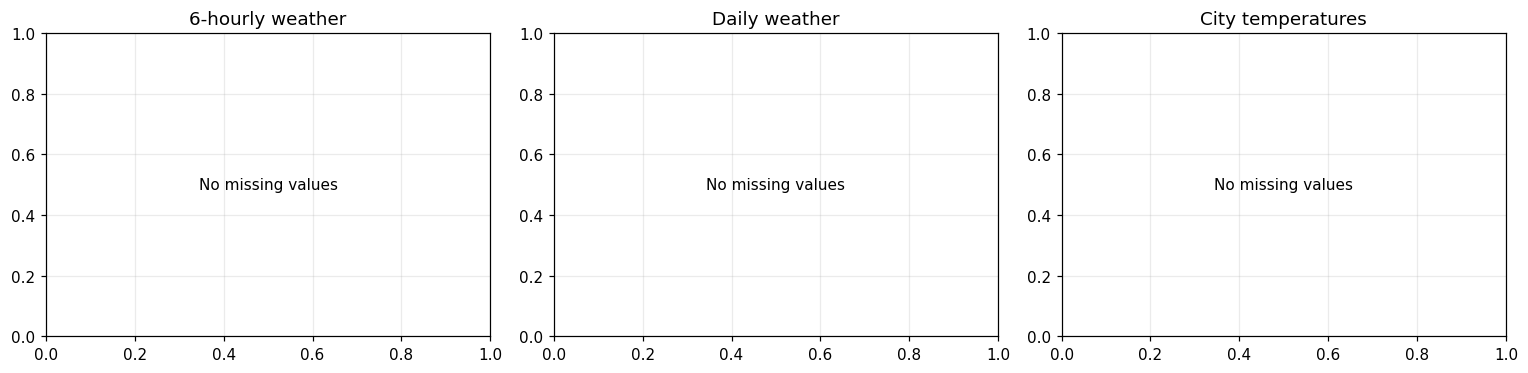

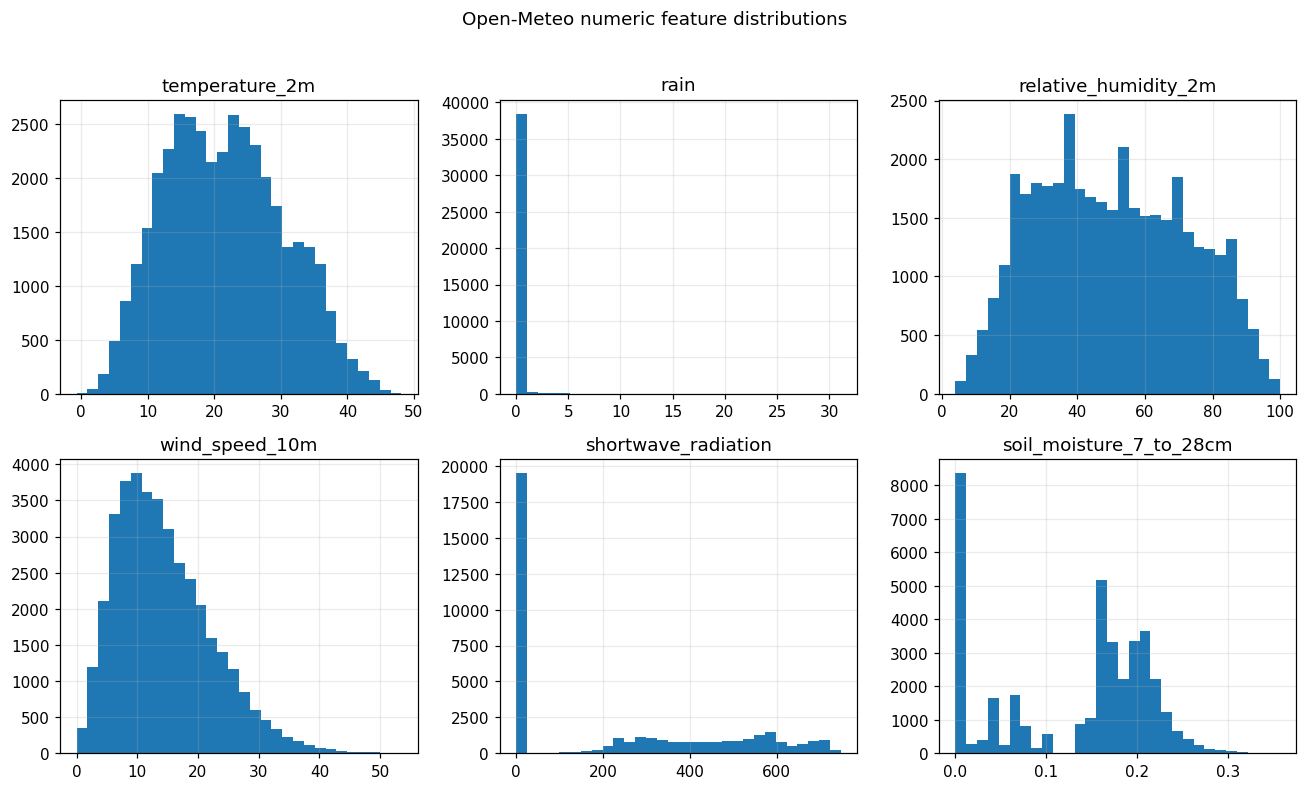

Cleaning complete: timestamps validated, duplicate records removed, numeric fields coerced.
Missing numeric values are retained here for transparent reporting and imputed inside model pipelines.


In [3]:
# Work on copies so the original loaded tables remain available for auditing.
six = six.copy()
daily = daily.copy()
tun = tun.copy()

# Normalize timestamps, remove duplicate records, and coerce expected numeric columns.
six["time"] = pd.to_datetime(six["time"], errors="coerce")
daily["time"] = pd.to_datetime(daily["time"], errors="coerce")
tun["date"] = pd.to_datetime(tun["date"], errors="coerce")
six = six.dropna(subset=["time"]).drop_duplicates(subset=["time"]).sort_values("time").reset_index(drop=True)
daily = daily.dropna(subset=["time"]).drop_duplicates(subset=["time"]).sort_values("time").reset_index(drop=True)
tun = tun.dropna(subset=["date"]).drop_duplicates().reset_index(drop=True)

for frame in (six, daily):
    for col in frame.columns:
        if col != "time":
            frame[col] = pd.to_numeric(frame[col], errors="coerce")
for col in ["Year", "Day_temp"]:
    if col in tun:
        tun[col] = pd.to_numeric(tun[col], errors="coerce")

def quality_report(frame, name):
    report = pd.DataFrame({
        "dtype": frame.dtypes.astype(str),
        "missing_n": frame.isna().sum(),
        "missing_pct": (100 * frame.isna().mean()).round(2),
        "unique_n": frame.nunique(dropna=True)
    })
    print(f"\\n{name}: {frame.shape[0]:,} rows × {frame.shape[1]} columns")
    print("Duplicate rows:", int(frame.duplicated().sum()))
    display(report.sort_values("missing_pct", ascending=False)) if "display" in globals() else print(report)

quality_report(six, "Open-Meteo 6-hourly")
quality_report(daily, "Open-Meteo daily")
quality_report(tun, "Tunisia city temperatures")

# Missingness visualization
fig, axes = plt.subplots(1, 3, figsize=(14, 3.5))
for ax, frame, title in zip(axes, [six, daily, tun], ["6-hourly weather", "Daily weather", "City temperatures"]):
    miss = (100 * frame.isna().mean()).sort_values(ascending=False)
    miss = miss[miss > 0].head(12)
    if len(miss):
        miss.sort_values().plot.barh(ax=ax)
        ax.set_xlabel("Missing values (%)")
    else:
        ax.text(.5, .5, "No missing values", ha="center", va="center", transform=ax.transAxes)
    ax.set_title(title)
plt.tight_layout(); plt.show()

# Numeric distributions help reveal implausible ranges and skew.
numeric_cols = [c for c in ["temperature_2m", "rain", "relative_humidity_2m",
                             "wind_speed_10m", "shortwave_radiation", "soil_moisture_7_to_28cm"] if c in six]
if numeric_cols:
    six[numeric_cols].hist(bins=30, figsize=(12, 7), layout=(-1, 3))
    plt.suptitle("Open-Meteo numeric feature distributions", y=1.02)
    plt.tight_layout(); plt.show()

print("Cleaning complete: timestamps validated, duplicate records removed, numeric fields coerced.")
print("Missing numeric values are retained here for transparent reporting and imputed inside model pipelines.")


## 2. Use the Tunisia city file to calibrate "heatwave"
Plain idea: for the cities closest to your site (set `HEAT_CITIES` below) we measure how many °C hotter than normal the hottest 5 % of days are.
That number becomes the strength of the synthetic heatwave scenario, so the heatwave is based on real Tunisian data rather than a guess.

Typical heatwave anomaly (top 5% days): +8.5 °C


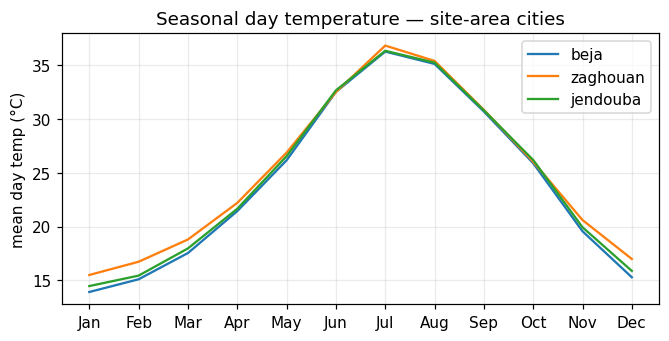

In [4]:
HEAT_CITIES = ["beja", "zaghouan", "jendouba"]      # cities near your site (change to match it: see the list printed above)
t = tun[tun.City.isin(HEAT_CITIES)].copy()
t["month_median"] = t.groupby(["City", "Month"]).Day_temp.transform("median")
t["anomaly"] = t.Day_temp - t.month_median
HW_DELTA = float(t.groupby("City").anomaly.apply(lambda s: s[s >= s.quantile(.95)].mean()).mean())
print(f"Typical heatwave anomaly (top 5% days): +{HW_DELTA:.1f} °C")

fig, ax = plt.subplots(figsize=(7, 3.2))
for c in HEAT_CITIES:
    d = t[t.City == c]
    ax.plot(d.groupby("Month").Day_temp.mean().reindex(months.keys()).values, label=c)
ax.set_xticks(range(12)); ax.set_xticklabels([m[:3] for m in months]); ax.set_ylabel("mean day temp (°C)"); ax.legend()
ax.set_title("Seasonal day temperature — site-area cities"); plt.show()

## 3. Site settings (declared assumptions — edit freely)
These numbers describe an imaginary rural community in Tunisia with irrigated farmland and a surface reservoir (dam/hill lake). They are **policy/design assumptions**, not measurements.

In [5]:
POP, LPCD, CLINIC_M3_DAY = 3000, 120, 20.0                  # people, litres/person/day, clinic m³/day
CROPS = ["olive", "cereal", "veg"]
AREA_HA = {"olive": 30, "cereal": 40, "veg": 8}
KC = {"olive": 0.65, "cereal": 0.80, "veg": 0.85}          # crop coefficients
SEASON = {"olive": range(1, 13), "cereal": [11, 12, 1, 2, 3, 4, 5], "veg": range(1, 13)}   # months when each crop is irrigated
R_CAP, PUMP_BLOCK = 8000.0, 2400.0                         # reservoir m³, pump m³/6h
BASE_INFLOW, CATCH_HA, RUNOFF = 250.0, 150.0, 0.15          # base inflow m³/6h (springs, upstream), catchment ha, runoff coefficient
E_PUMP = 0.6                                                # kWh per m³ pumped
PV_KWP, PV_PR, BLOCK_H = 250.0, 0.8, 6                      # solar kWp, performance ratio, hours per block
B_CAP, B_PMAX, ETA = 600.0, 450.0, 0.95                     # battery kWh, max kWh/block, one-way efficiency
GRID_BLOCK = 900.0                                          # kWh available from grid per 6h block when grid is up
HH_PROF = np.array([.10, .35, .30, .25]); CL_PROF = np.array([.15, .30, .30, .25]); IRR_PROF = np.array([.35, .25, .10, .30])
SECTORS = ["clinic", "household", "olive", "cereal", "veg"]   # priority order
W = np.array([1000., 300., 10., 6., 4.])                    # declared priority weights (policy)
V_WATER, V_BATT, GRID_COST = 1.0, 0.25, 0.02
IRR_SAFETY = np.array([1, 1, 1.1, 1.1, 1.1])                # safety margin on forecast crop demand (forecast error buffer)                # small values to avoid draining reserves / wasting grid

## 4. Site simulation engine (SYNTHETIC)
Real weather goes in; the simulator adds crises (heatwave, drought = low inflow, blackout, pump failure...) and computes demand and solar production.
**Everything produced here is simulation-generated, not observed.**

In [6]:
SCEN = ["normal", "heatwave", "water_shortage", "blackout", "drought", "pump_failure", "combined_crisis"]
P_SCEN = [.35, .15, .12, .12, .10, .08, .08]

def make_days(dates, rng):
    n = len(dates)
    sc = rng.choice(SCEN, size=n, p=P_SCEN)
    s = pd.Series(sc)
    dry = s.isin(["water_shortage", "drought", "combined_crisis"]).values
    out = s.isin(["blackout", "combined_crisis"]).values
    hot = s.isin(["heatwave", "combined_crisis"]).values
    pump = s.isin(["pump_failure", "combined_crisis"]).values
    D = pd.DataFrame({"date": dates, "scenario": sc})
    D["anom"] = np.where(hot, rng.uniform(.5, 1, n) * HW_DELTA, 0.0)
    D["rech_f"] = np.where(dry, rng.uniform(.2, .5, n), rng.uniform(.8, 1.1, n))
    D["pump_f"] = np.where(pump, rng.uniform(.2, .5, n), 1.0)
    D["R0"] = np.where(dry, rng.uniform(.05, .35, n), rng.uniform(.4, 1, n)) * R_CAP
    D["B0"] = np.where(out, rng.uniform(.05, .5, n), rng.uniform(.4, 1, n)) * B_CAP
    p_out = np.where(out, .7, .02)
    G = (rng.random((n, 4)) > p_out[:, None]).astype(int)
    for k in range(4):
        D[f"g{k}"] = G[:, k]
    return D

def et0_turc(Tm, Rs_W, RH):
    """Turc reference evapotranspiration (mm/day) from daily temperature, radiation, humidity."""
    Rs = Rs_W * 0.0864
    et = 0.013 * (np.clip(Tm, 0, None) / (np.clip(Tm, 0, None) + 15)) * (23.9 * Rs + 50)
    et = np.where(RH < 50, et * (1 + (50 - RH) / 70), et)
    return np.clip(et, 0, None)

def build_blocks(six, rng):
    w = six[["time", "temperature_2m", "rain", "relative_humidity_2m", "weather_code", "wind_speed_10m",
             "soil_moisture_7_to_28cm", "shortwave_radiation", "global_tilted_irradiance"]].copy()
    w.columns = ["time", "temp", "rain", "rh", "wcode", "wind", "sm", "rad", "gti"]
    for c in w.columns[1:]:
        w[c] = pd.to_numeric(w[c], errors="coerce")
    w = w.dropna().sort_values("time").reset_index(drop=True)
    w["wind"] = w["wind"] / 3.6
    w["date"] = w.time.dt.normalize(); w["hour"] = w.time.dt.hour
    ok = w.groupby("date").hour.transform("count") == 4          # keep only complete days
    w = w[ok].reset_index(drop=True)
    days = make_days(np.sort(w.date.unique()), rng)
    B = w.merge(days, on="date")
    B["temp"] = B.temp + B.anom
    B["rh"] = (B.rh - 2 * B.anom).clip(5, 100)
    g = B.groupby("date")
    B["temp_dm"] = g.temp.transform("mean"); B["rad_dm"] = g.rad.transform("mean")
    B["rh_dm"] = g.rh.transform("mean"); B["sm_dm"] = g.sm.transform("mean")
    B["rain_day"] = g.rain.transform("sum") * 6
    blk = (B.hour // 6).values; n = len(B)
    B["blk"] = blk
    B["grid_ok"] = B[["g0", "g1", "g2", "g3"]].values[np.arange(n), blk]
    B["pump_cap"] = PUMP_BLOCK * B.pump_f
    B["rech"] = (BASE_INFLOW + RUNOFF * CATCH_HA * 10 * B.rain * 6) * B.rech_f    # reservoir inflow per block: base flow + rainfall runoff
    B["reservoir"] = B.R0
    low = (B.R0 / R_CAP < 0.2).values                              # people/farmers save water when the reservoir is low
    T = B.temp.values
    B["dem_clinic"] = CLINIC_M3_DAY * CL_PROF[blk] * (1 + .015 * np.clip(T - 25, 0, None)) * rng.lognormal(0, .04, n)
    B["dem_household"] = POP * LPCD / 1000 * HH_PROF[blk] * (1 + .025 * np.clip(T - 25, 0, None)) * np.where(low, .9, 1) * rng.lognormal(0, .05, n)
    et0 = et0_turc(B.temp_dm.values, 0.75 * B.rad_dm.values, B.rh_dm.values)   # 0.75: 4 daily samples overstate mean radiation
    for c in CROPS:
        in_season = B.date.dt.month.isin(list(SEASON[c])).values
        need = in_season * np.clip(KC[c] * et0 * (1 - .5 * np.clip(B.sm_dm.values / .25, 0, 1)) - .8 * B.rain_day.values, 0, None)
        B[f"dem_{c}"] = need * AREA_HA[c] * 10 * IRR_PROF[blk] * np.where(low, .85, 1) * rng.lognormal(0, .06, n)
    B["solar"] = (PV_KWP * B.gti / 1000 * PV_PR * BLOCK_H * (1 - .004 * np.clip(T + .03 * B.gti.values - 25, 0, None))
                  * rng.lognormal(0, .03, n))
    for c in ["dem_clinic", "dem_household", "dem_olive", "dem_cereal", "dem_veg", "solar"]:
        B["prev_" + c] = B[c].shift(1).bfill()
    return B.sort_values("time").reset_index(drop=True)

B = build_blocks(six, rng)
print(B.shape, B.date.min().date(), "→", B.date.max().date())
print(B.groupby("scenario").size().rename("blocks"))
B[["time", "scenario", "temp", "dem_household", "dem_clinic", "dem_olive", "solar"]].head(8)

(39080, 43) 2000-01-01 → 2026-09-30
scenario
blackout            4668
combined_crisis     3096
drought             3848
heatwave            5772
normal             13804
pump_failure        3064
water_shortage      4828
Name: blocks, dtype: int64


,time,scenario,temp,dem_household,dem_clinic,dem_olive,solar
0,2000-01-01 00:00:00,drought,7.000000,39.990916,3.164941,50.710696,0.000000
1,2000-01-01 06:00:00,drought,4.100000,130.815804,5.957144,37.327931,0.000000
2,2000-01-01 12:00:00,drought,10.500000,112.033165,6.032663,15.477923,283.373320
3,2000-01-01 18:00:00,drought,10.400000,96.016104,4.788019,46.207050,378.333073
4,2000-01-02 00:00:00,heatwave,12.783457,38.065887,2.974147,67.867144,0.000000
5,2000-01-02 06:00:00,heatwave,10.783457,124.803353,5.790033,55.899193,0.000000
6,2000-01-02 12:00:00,heatwave,18.383457,119.315419,6.011737,23.650564,296.909197
7,2000-01-02 18:00:00,heatwave,18.483457,87.386653,5.126003,71.489224,386.944504


## 4b. Feature engineering, correlations and PCA diagnostics

The simulator already creates domain features such as 6-hour block, daily weather summaries, rain totals,
reservoir state and previous-block demand/solar. Here we add cyclical calendar encodings and inspect
correlations. PCA is used as an exploratory dimensionality diagnostic, not forced into the tree models:
tree ensembles generally do not need PCA, and retaining original features makes explanations clearer.


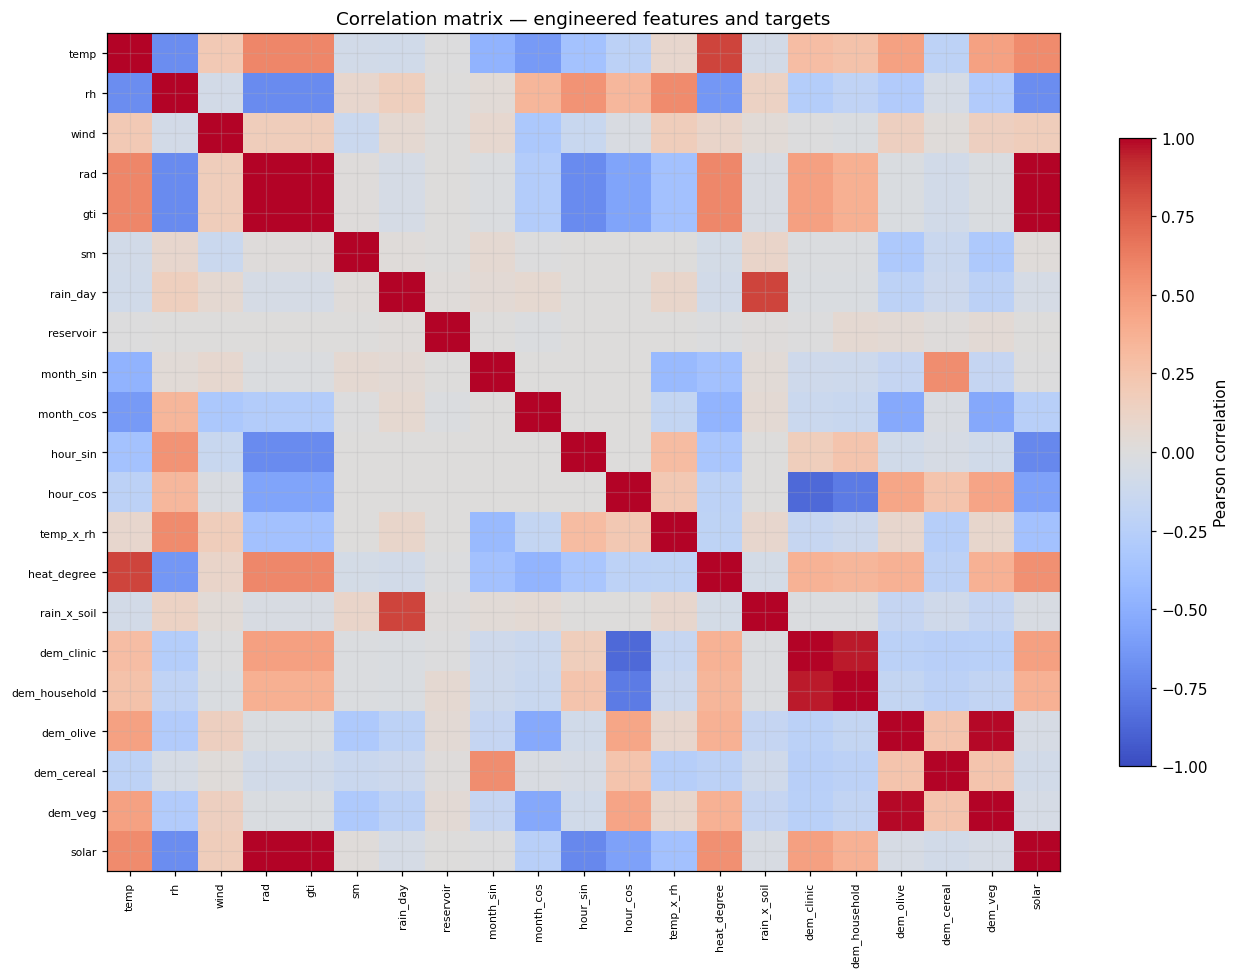

Strongest absolute correlations with dem_household:


,feature,abs_correlation
0,dem_clinic,0.960
1,hour_cos,0.776
2,rad,0.383
3,gti,0.383
4,solar,0.375
5,heat_degree,0.337
6,temp,0.259
7,hour_sin,0.245


Strongest absolute correlations with solar:


,feature,abs_correlation
0,gti,0.997
1,rad,0.997
2,hour_sin,0.712
3,rh,0.693
4,hour_cos,0.581
5,temp,0.563
6,heat_degree,0.544
7,dem_clinic,0.463


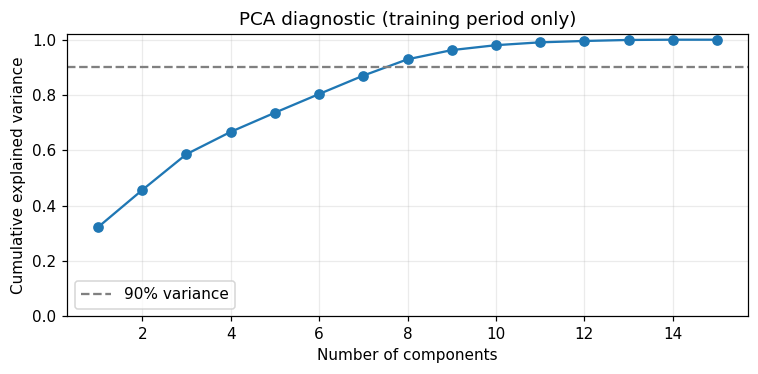

Components for 90% variance: 8 of 15
PCA is diagnostic only; tree models below use the engineered original features.


In [7]:
# Calendar feature engineering on the block-level modelling table.
B = B.copy()
B["month_sin"] = np.sin(2 * np.pi * B.date.dt.month / 12)
B["month_cos"] = np.cos(2 * np.pi * B.date.dt.month / 12)
B["dayofyear_sin"] = np.sin(2 * np.pi * B.date.dt.dayofyear / 365.25)
B["dayofyear_cos"] = np.cos(2 * np.pi * B.date.dt.dayofyear / 365.25)
B["hour_sin"] = np.sin(2 * np.pi * B.hour / 24)
B["hour_cos"] = np.cos(2 * np.pi * B.hour / 24)
B["temp_x_rh"] = B.temp * B.rh / 100
B["heat_degree"] = np.clip(B.temp - 25, 0, None)
B["rain_x_soil"] = B.rain_day * B.sm_dm

# Correlations of weather, engineered predictors and key targets.
corr_cols = [c for c in [
    "temp", "rh", "wind", "rad", "gti", "sm", "rain_day", "reservoir",
    "month_sin", "month_cos", "hour_sin", "hour_cos", "temp_x_rh",
    "heat_degree", "rain_x_soil", "dem_clinic", "dem_household",
    "dem_olive", "dem_cereal", "dem_veg", "solar"
] if c in B.columns]
corr = B[corr_cols].corr(numeric_only=True)
fig, ax = plt.subplots(figsize=(12, 9))
im = ax.imshow(corr, vmin=-1, vmax=1, cmap="coolwarm", aspect="auto")
ax.set_xticks(range(len(corr.columns))); ax.set_xticklabels(corr.columns, rotation=90, fontsize=7)
ax.set_yticks(range(len(corr.columns))); ax.set_yticklabels(corr.columns, fontsize=7)
ax.set_title("Correlation matrix — engineered features and targets")
fig.colorbar(im, ax=ax, shrink=.75, label="Pearson correlation")
plt.tight_layout(); plt.show()

# Show strongest absolute relationships with the main targets.
for target in ["dem_household", "solar"]:
    ranked = corr[target].drop(target).abs().sort_values(ascending=False).head(8)
    print(f"Strongest absolute correlations with {target}:")
    display(pd.DataFrame({"feature": ranked.index, "abs_correlation": ranked.values.round(3)}))

# PCA diagnostic on training predictors only. PCA is not used automatically downstream.
pca_cols = [c for c in ["temp", "rh", "wind", "rad", "gti", "sm", "rain_day",
                         "reservoir", "month_sin", "month_cos", "hour_sin", "hour_cos",
                         "temp_x_rh", "heat_degree", "rain_x_soil"] if c in B.columns]
pca_train = B.loc[(B.date.dt.year <= 2019), pca_cols].replace([np.inf, -np.inf], np.nan)
pca_pipe = make_pipeline(SimpleImputer(strategy="median"), StandardScaler(), PCA())
pca_pipe.fit(pca_train)
pca_model = pca_pipe.named_steps["pca"]
cumvar = np.cumsum(pca_model.explained_variance_ratio_)
fig, ax = plt.subplots(figsize=(7, 3.5))
ax.plot(np.arange(1, len(cumvar)+1), cumvar, marker="o")
ax.axhline(.90, linestyle="--", color="grey", label="90% variance")
ax.set(xlabel="Number of components", ylabel="Cumulative explained variance",
       title="PCA diagnostic (training period only)", ylim=(0, 1.02))
ax.legend(); plt.tight_layout(); plt.show()
print("Components for 90% variance:", int(np.searchsorted(cumvar, .90) + 1), "of", len(pca_cols))
print("PCA is diagnostic only; tree models below use the engineered original features.")


## 5. Random Forest regressors (demand + solar)
- **Train:** 2000–2019, *without* the `combined_crisis` days (kept hidden on purpose).
- **Test:** 2020–2026, all scenarios, including the combined crises the model never saw.
- Each model also gets a *previous value* feature (as in your document). For the 24 h forecast the model feeds its own previous prediction forward, step by step.
- We compare with a naive baseline ("same as the previous block") so the score means something.

household: selected XGBoost (Boosting) | test MAE=3.875
clinic: selected HistGradientBoosting (Boosting) | test MAE=0.169
irrigation: selected Extra Trees (Bagging) | test MAE=9.096
solar: selected Random Forest (Bagging) | test MAE=6.331
\nRegression model comparison (lower MAE/RMSE is better):


,target,family,model,MAE,RMSE,naive_MAE
0,clinic,Boosting,HistGradientBoosting,0.169,0.219,1.719
1,clinic,Boosting,XGBoost,0.169,0.220,1.719
2,clinic,Bagging,Random Forest,0.169,0.219,1.719
3,clinic,Bagging,Extra Trees,0.170,0.220,1.719
4,clinic,Boosting,AdaBoost,0.190,0.250,1.719
5,household,Boosting,XGBoost,3.875,5.245,46.533
6,household,Boosting,HistGradientBoosting,3.885,5.259,46.533
7,household,Bagging,Random Forest,3.914,5.320,46.533
8,household,Bagging,Extra Trees,3.961,5.374,46.533
9,household,Boosting,AdaBoost,6.359,8.490,46.533


\nSelected model per regression target:


,target,family,model,MAE,RMSE,naive_MAE
0,clinic,Boosting,HistGradientBoosting,0.169,0.219,1.719
5,household,Boosting,XGBoost,3.875,5.245,46.533
10,irrigation,Bagging,Extra Trees,9.096,18.815,59.558
15,solar,Bagging,Random Forest,6.331,11.700,271.377


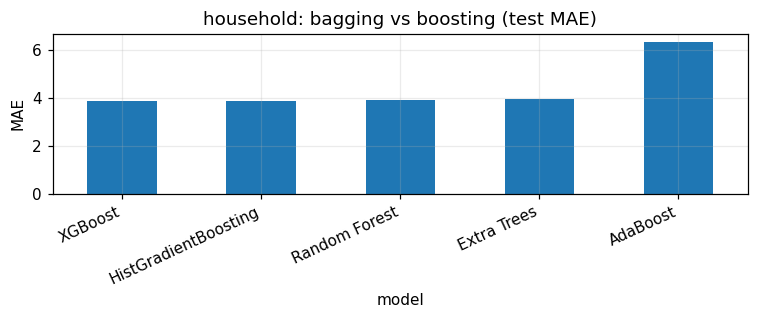

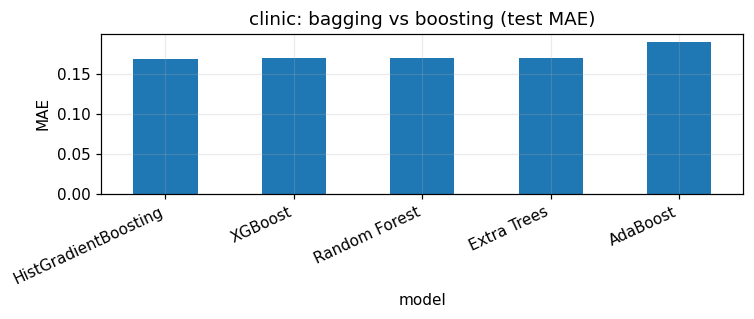

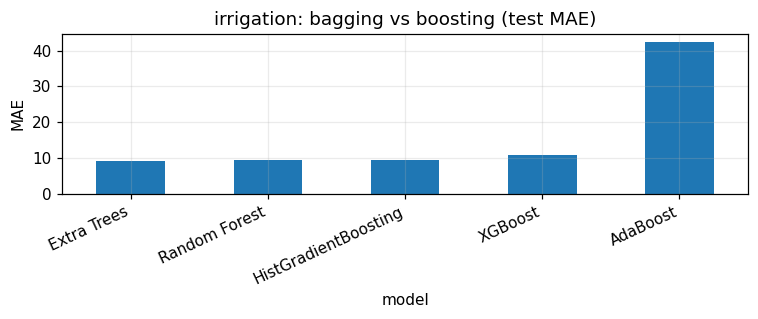

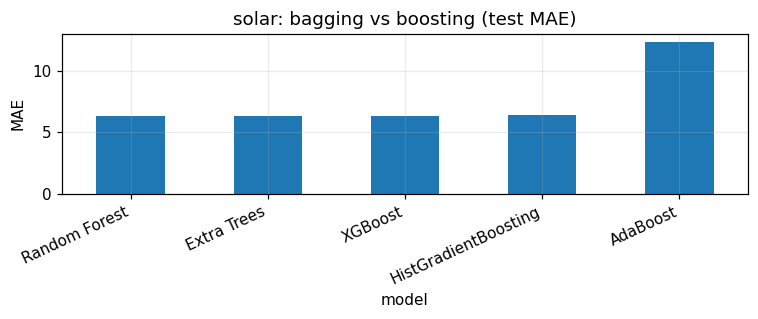

In [8]:
WX = ["temp", "rh", "rad", "gti", "wind", "hour", "sm", "wcode", "temp_dm", "rad_dm", "rh_dm", "sm_dm", "rain_day", "reservoir",
      "month_sin", "month_cos", "dayofyear_sin", "dayofyear_cos", "hour_sin", "hour_cos", "temp_x_rh", "heat_degree", "rain_x_soil"]
WX_SOLAR = ["temp", "rh", "rad", "gti", "wind", "hour", "wcode", "temp_dm", "rad_dm",
            "month_sin", "month_cos", "dayofyear_sin", "dayofyear_cos", "hour_sin", "hour_cos", "temp_x_rh", "heat_degree"]
FEATS = {"household": WX + ["prev"], "clinic": WX + ["prev"],
         "irrigation": WX + ["crop_type", "prev"], "solar": WX_SOLAR + ["prev"]}

def long_frame(df, target):
    if target == "irrigation":
        parts = []
        for i, c in enumerate(CROPS):
            p = df[WX + ["date", "scenario"]].copy()
            p["crop_type"] = i; p["y"] = df[f"dem_{c}"].values; p["prev"] = df[f"prev_dem_{c}"].values
            parts.append(p)
        return pd.concat(parts, ignore_index=True)
    col = {"household": "dem_household", "clinic": "dem_clinic", "solar": "solar"}[target]
    p = df[WX + ["date", "scenario"]].copy()
    p["y"] = df[col].values; p["prev"] = df["prev_" + col].values
    return p

is_train = (B.date.dt.year <= 2019) & (B.scenario != "combined_crisis")
is_test = B.date.dt.year >= 2020

# Candidate estimators are grouped explicitly by ensemble strategy.
def regression_candidates():
    bagging = {
        "Random Forest": RandomForestRegressor(n_estimators=250, max_depth=12, min_samples_leaf=2, random_state=SEED, n_jobs=-1),
        "Extra Trees": ExtraTreesRegressor(n_estimators=250, max_depth=14, min_samples_leaf=2, random_state=SEED, n_jobs=-1)
    }
    boosting = {
        "AdaBoost": AdaBoostRegressor(n_estimators=180, learning_rate=.05, random_state=SEED),
        "HistGradientBoosting": HistGradientBoostingRegressor(max_iter=220, learning_rate=.06, max_leaf_nodes=20, l2_regularization=1.0, random_state=SEED)
    }
    if XGBOOST_AVAILABLE:
        boosting["XGBoost"] = XGBRegressor(n_estimators=250, max_depth=5, learning_rate=.05,
            subsample=.85, colsample_bytree=.85, reg_lambda=2, objective="reg:squarederror",
            random_state=SEED, n_jobs=-1)
    return {"Bagging": bagging, "Boosting": boosting}

reg_candidates = regression_candidates()
models, rows, reg_family_rows = {}, [], []
for tg in FEATS:
    tr, te = long_frame(B[is_train], tg), long_frame(B[is_test], tg)
    Xtr, Xte = tr[FEATS[tg]], te[FEATS[tg]]
    best = None
    for family, candidates in reg_candidates.items():
        for name, estimator in candidates.items():
            pipe = make_pipeline(SimpleImputer(strategy="median"), clone(estimator))
            pipe.fit(Xtr, tr.y)
            pred = pipe.predict(Xte)
            mae = mean_absolute_error(te.y, pred)
            rmse = mean_squared_error(te.y, pred) ** .5
            naive = mean_absolute_error(te.y, te.prev)
            rows.append(dict(target=tg, family=family, model=name, MAE=mae, RMSE=rmse, naive_MAE=naive))
            if best is None or mae < best[0]:
                best = (mae, family, name, pipe)
    models[tg] = best[3]
    print(f"{tg}: selected {best[2]} ({best[1]}) | test MAE={best[0]:.3f}")

reg_comparison = pd.DataFrame(rows).sort_values(["target", "MAE"]).reset_index(drop=True)
reg_report = pd.DataFrame([
    dict(model=tg, subset=subset,
         MAE=mean_absolute_error((te := long_frame(B[is_test], tg)).y, models[tg].predict(te[FEATS[tg]])),
         RMSE=mean_squared_error(te.y, models[tg].predict(te[FEATS[tg]])) ** .5,
         naive_MAE=mean_absolute_error(te.y, te.prev))
    for tg in FEATS for subset in ["all test"]
]).round(3)

print("\\nRegression model comparison (lower MAE/RMSE is better):")
display(reg_comparison.round(3))
print("\\nSelected model per regression target:")
display(reg_comparison.loc[reg_comparison.groupby("target").MAE.idxmin()].round(3))

# Plot the comparison grouped into bagging and boosting families.
for target in FEATS:
    sub = reg_comparison[reg_comparison.target == target].sort_values("MAE")
    ax = sub.plot.bar(x="model", y="MAE", figsize=(7, 3), legend=False, title=f"{target}: bagging vs boosting (test MAE)")
    ax.set_ylabel("MAE"); plt.xticks(rotation=25, ha="right"); plt.tight_layout(); plt.show()


**How to read this table:** `MAE` is the average error in the unit of the target (m³ per 6 h for water, kWh per 6 h for solar). If `MAE` is clearly lower than `naive_MAE`, the forest adds value beyond copying the last block.

⚠️ Honest note: demand and solar here are *formulas of the weather plus noise*, so a good score mostly proves the forest can learn the simulator. It does **not** prove accuracy on a real oasis.

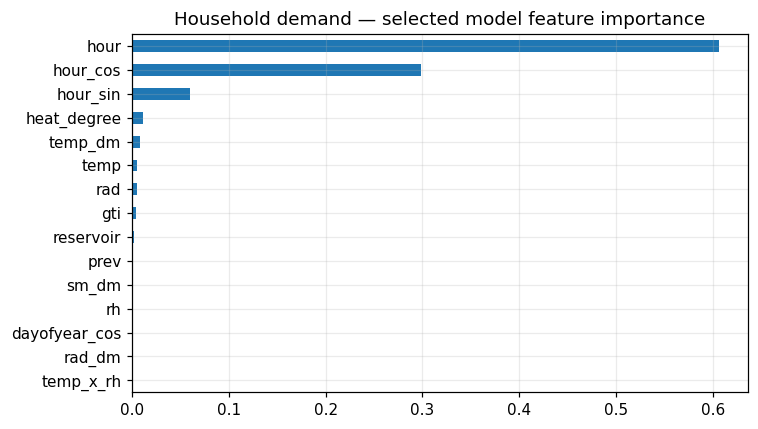

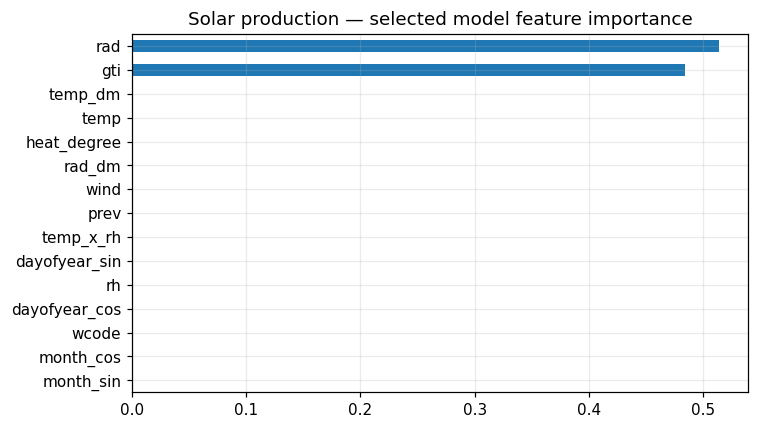

In [9]:
def fitted_tree_estimator(pipe):
    return pipe.steps[-1][1]
for target, title in [("household", "Household demand"), ("solar", "Solar production")]:
    estimator = fitted_tree_estimator(models[target])
    if hasattr(estimator, "feature_importances_"):
        vals = pd.Series(estimator.feature_importances_, index=FEATS[target]).sort_values()
        vals.tail(15).plot.barh(figsize=(7, 4), title=f"{title} — selected model feature importance")
        plt.tight_layout(); plt.show()
    else:
        print(f"{target}: selected estimator does not expose impurity feature importances.")


## 6. 24-hour forecast helper
For each day it predicts the 4 blocks one after another. **Weather inputs are the real archived weather** here; in real use you would plug in a weather *forecast* (e.g. the Open-Meteo forecast API).

In [10]:
SEC_COLS = ["dem_clinic", "dem_household", "dem_olive", "dem_cereal", "dem_veg"]

def forecast_days(models, D):
    D = D.reset_index(drop=True); nd = len(D) // 4; first = np.arange(nd) * 4
    def run(tg, prev_col, crop=None):
        P = np.zeros((nd, 4)); prev = D.loc[first, prev_col].values
        for k in range(4):
            X = D.iloc[first + k][[c for c in FEATS[tg] if c not in ("prev", "crop_type")]].copy()
            if crop is not None: X["crop_type"] = crop
            X["prev"] = prev
            P[:, k] = models[tg].predict(X[FEATS[tg]]); prev = P[:, k]
        return P
    dem = np.stack([run("clinic", "prev_dem_clinic"), run("household", "prev_dem_household")] +
                   [run("irrigation", f"prev_dem_{c}", i) for i, c in enumerate(CROPS)], axis=2)   # (nd,4,5)
    return dem, run("solar", "prev_solar")

def day_arrays(D):
    D = D.reset_index(drop=True); nd = len(D) // 4; f = np.arange(nd) * 4
    return dict(dates=D.date.values[f], scenario=D.scenario.values[f],
                dem=D[SEC_COLS].values.reshape(nd, 4, 5), solar=D.solar.values.reshape(nd, 4),
                grid=D.grid_ok.values.reshape(nd, 4), pump=D.pump_cap.values[f], rech=D.rech.values.reshape(nd, 4),
                R0=D.R0.values[f], B0=D.B0.values[f], temp=D.temp_dm.values[f], sm=D.sm_dm.values[f])

AR = day_arrays(B)
te_mask_days = pd.to_datetime(AR["dates"]).year >= 2020
D_test = B[is_test].reset_index(drop=True)
F_dem, F_sol = forecast_days(models, D_test)
print("forecast shapes:", F_dem.shape, F_sol.shape)

forecast shapes: (2465, 4, 5) (2465, 4)


## 7. The two decision makers
- **Human baseline:** serves clinic → households → olives → cereals → vegetables, block by block, using whatever is available *right now* (no look-ahead, no battery planning).
- **AI optimizer:** linear program over the remaining blocks of the day (water balance, pump limit, solar/grid/battery energy). It can hold water back now to protect essential needs later. It is re-solved each block (receding horizon) using the forecasts, and executed against the *true* solar and demand (clinic and household meters are read live, so those two are always topped up to their real demand when physically possible).

In [11]:
def execute(R, Bt, want, solar, grid_ok, pump_cap, rech):
    """Apply a desired water allocation `want` (5 sectors) to the physical system. Returns what is really delivered."""
    R = R + rech
    e_av = solar + GRID_BLOCK * grid_ok + ETA * min(Bt, B_PMAX)
    cap_w, cap_e = min(pump_cap, R), e_av / E_PUMP
    cap, rem, served = min(cap_w, cap_e), min(cap_w, cap_e), np.zeros(5)
    for k in range(5):
        served[k] = min(want[k], rem); rem -= served[k]
    Wt = served.sum(); E = Wt * E_PUMP
    s = min(solar, E); r = E - s; g = min(GRID_BLOCK * grid_ok, r); r -= g; d = r / ETA
    Bt2 = Bt - d
    ch = max(0.0, min(solar - s, B_PMAX, (B_CAP - Bt2) / ETA)); Bt2 += ETA * ch
    lost = max(0.0, min(want.sum(), cap_w) - cap_e)                # water not delivered because of ENERGY shortage
    return served, min(R - Wt, R_CAP), Bt2, E, lost

def solve_lp(R0, B0, dem, solar, grid, pump_cap, rech):
    """24h (or shorter) allocation. dem:(T,5) solar:(T,) grid:(T,) -> dict with plan."""
    T = len(dem); nv = 12; N = T * nv; ix = lambda t, j: t * nv + j
    # variable layout per block: 0-4 water to sectors | 5 solar→pump | 6 grid→pump | 7 battery discharge | 8 battery charge | 9 reservoir | 10 battery level | 11 spill
    c = np.zeros(N); hi = np.full(N, np.inf)
    for t in range(T):
        for k in range(5):
            c[ix(t, k)] = -W[k]; hi[ix(t, k)] = dem[t][k]
        hi[ix(t, 5)] = solar[t]; hi[ix(t, 6)] = GRID_BLOCK * grid[t]; c[ix(t, 6)] = GRID_COST
        hi[ix(t, 7)] = B_PMAX; hi[ix(t, 8)] = B_PMAX; hi[ix(t, 9)] = R_CAP; hi[ix(t, 10)] = B_CAP
    c[ix(T - 1, 9)] -= V_WATER; c[ix(T - 1, 10)] -= V_BATT
    Aeq, beq = np.zeros((2 * T, N)), np.zeros(2 * T)
    Aub, bub = np.zeros((3 * T, N)), np.zeros(3 * T)
    for t in range(T):
        r = 2 * t
        for k in range(5): Aeq[r, ix(t, k)] = 1
        Aeq[r, ix(t, 9)] = 1; Aeq[r, ix(t, 11)] = 1
        if t == 0: beq[r] = R0 + rech[t]
        else: Aeq[r, ix(t - 1, 9)] = -1; beq[r] = rech[t]
        r = 2 * t + 1
        Aeq[r, ix(t, 10)] = 1; Aeq[r, ix(t, 8)] = -ETA; Aeq[r, ix(t, 7)] = 1
        if t == 0: beq[r] = B0
        else: Aeq[r, ix(t - 1, 10)] = -1
        for k in range(5):
            Aub[3 * t, ix(t, k)] = E_PUMP; Aub[3 * t + 1, ix(t, k)] = 1
        Aub[3 * t, ix(t, 5)] = -1; Aub[3 * t, ix(t, 6)] = -1; Aub[3 * t, ix(t, 7)] = -ETA
        bub[3 * t + 1] = pump_cap
        Aub[3 * t + 2, ix(t, 5)] = 1; Aub[3 * t + 2, ix(t, 8)] = 1; bub[3 * t + 2] = solar[t]
    res = linprog(c, A_ub=Aub, b_ub=bub, A_eq=Aeq, b_eq=beq, bounds=list(zip(np.zeros(N), hi)), method="highs")
    if res.status != 0:
        return dict(ok=False)
    x = res.x.reshape(T, nv)
    return dict(ok=True, water=x[:, :5], solar_used=x[:, 5], grid=x[:, 6], batt_discharge=x[:, 7], batt_charge=x[:, 8],
                reservoir=x[:, 9], battery=x[:, 10], spill=x[:, 11])

def run_day(policy, a, i, F=None):
    """Simulate one day i of arrays `a`. policy: 'human' | 'lp'. F=(forecast_dem, forecast_solar) for the LP (None = perfect forecast)."""
    R, Bt = a["R0"][i], a["B0"][i]; served = np.zeros((4, 5)); E = 0.0; lost = 0.0; plan0 = None
    for t in range(4):
        if policy == "human":
            want = a["dem"][i, t]
        else:
            fd = a["dem"][i, t:] if F is None else F[0][i, t:] * IRR_SAFETY   # +10 % buffer on forecast irrigation
            fs = a["solar"][i, t:] if F is None else F[1][i, t:]
            pl = solve_lp(R, Bt, fd, fs, a["grid"][i, t:], a["pump"][i], a["rech"][i, t:])
            want = np.minimum(pl["water"][0], a["dem"][i, t]) if pl["ok"] else a["dem"][i, t]
            want[:2] = a["dem"][i, t][:2]                   # clinic & households are metered live: always top up to real demand
            if t == 0: plan0 = pl
        s, R, Bt, e, l = execute(R, Bt, want, a["solar"][i, t], a["grid"][i, t], a["pump"][i], a["rech"][i, t])
        served[t] = s; E += e; lost += l
    dem = a["dem"][i]
    return dict(served=served, dem=dem, energy=E, end_R=R, end_B=Bt, lost_energy=lost, plan0=plan0)

def metrics(r):
    d, s = r["dem"].sum(0), r["served"].sum(0)
    return dict(unmet_pct=100 * (1 - s.sum() / d.sum()), clinic_cov=100 * s[0] / d[0], household_cov=100 * s[1] / d[1],
                irrigation_cov=100 * s[2:].sum() / max(d[2:].sum(), 1e-9), energy_kwh=r["energy"], end_reservoir=r["end_R"], end_battery=r["end_B"])

# quick self-check of the LP on one random day: constraints must hold
i0 = int(np.where(te_mask_days)[0][5])
pl = solve_lp(AR["R0"][i0], AR["B0"][i0], AR["dem"][i0], AR["solar"][i0], AR["grid"][i0], AR["pump"][i0], AR["rech"][i0])
assert pl["ok"] and (pl["water"].sum(1) <= AR["pump"][i0] + 1e-6).all() and (pl["reservoir"] >= -1e-6).all()
assert (E_PUMP * pl["water"].sum(1) <= pl["solar_used"] + pl["grid"] + ETA * pl["batt_discharge"] + 1e-6).all()
print("LP feasibility check passed ✔")

LP feasibility check passed ✔


## 8. Random Forest classifiers — risk of shortage (low / medium / high)
**Where do the labels come from?** We run the *human baseline* through the simulator for every day and measure what actually went short:
- **Water risk:** share of clinic + household demand not delivered (<1 % low, 1–10 % medium, >10 % high)
- **Energy risk:** share of demand lost because pumping energy ran out (<2 % low, 2–10 % medium, >10 % high)
- **Agricultural stress:** share of irrigation demand not delivered (<10 % low, 10–40 % medium, >40 % high)

The classifier then learns to predict these labels **before** the day happens, from the forecasts and the current state.

water [8686  166  918] (low, medium, high)
energy [8355  240 1175] (low, medium, high)
agri [7214 1120 1436] (low, medium, high)
\n=== water risk — selected XGBoost (Boosting) | macro-F1=0.677 ===
              precision    recall  f1-score   support

         low       0.96      0.97      0.96      2114
      medium       0.44      0.23      0.31        47
        high       0.78      0.75      0.76       304

    accuracy                           0.93      2465
   macro avg       0.73      0.65      0.68      2465
weighted avg       0.92      0.93      0.93      2465

\n=== energy risk — selected XGBoost (Boosting) | macro-F1=0.670 ===
              precision    recall  f1-score   support

         low       0.98      0.98      0.98      2036
      medium       0.35      0.12      0.18        68
        high       0.82      0.90      0.86       361

    accuracy                           0.95      2465
   macro avg       0.71      0.67      0.67      2465
weighted avg       0.94    

,risk,family,model,macro_F1
13,agri,Boosting,HistGradientBoosting,0.754
14,agri,Boosting,XGBoost,0.738
11,agri,Bagging,Extra Trees,0.730
10,agri,Bagging,Random Forest,0.696
12,agri,Boosting,AdaBoost,0.332
9,energy,Boosting,XGBoost,0.670
8,energy,Boosting,HistGradientBoosting,0.653
6,energy,Bagging,Extra Trees,0.648
5,energy,Bagging,Random Forest,0.611
7,energy,Boosting,AdaBoost,0.592


,risk,family,model,macro_F1
13,agri,Boosting,HistGradientBoosting,0.754
9,energy,Boosting,XGBoost,0.670
4,water,Boosting,XGBoost,0.677


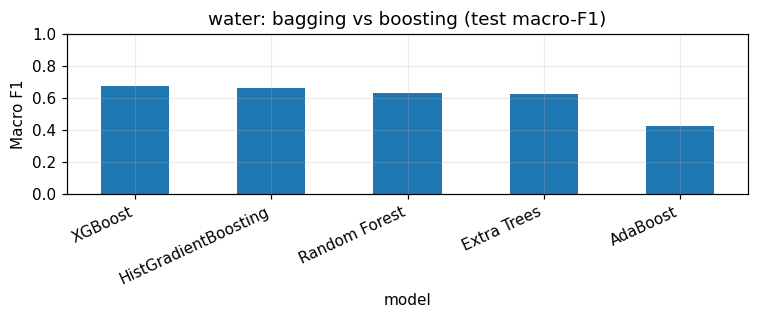

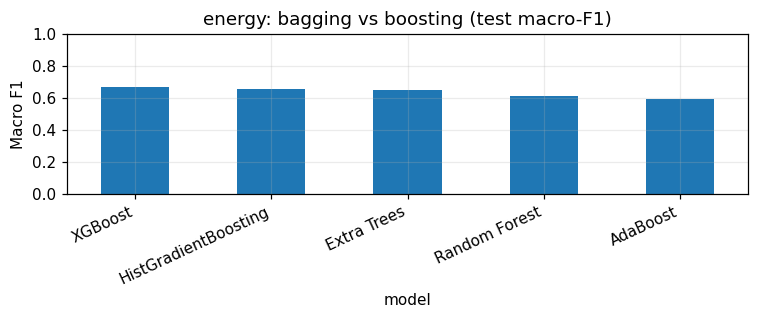

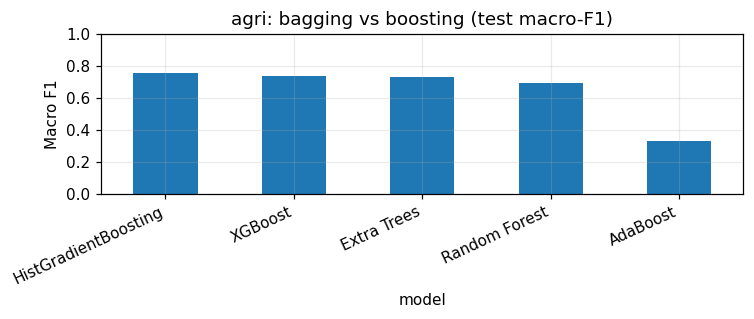

In [12]:
def bucket(x, lo, hi):
    return np.where(x < lo, 0, np.where(x < hi, 1, 2))

nd = len(AR["dates"]); lab = np.zeros((nd, 3))
for i in range(nd):
    r = run_day("human", AR, i); d, s = r["dem"].sum(0), r["served"].sum(0)
    lab[i] = [100 * (1 - (s[:2].sum()) / d[:2].sum()), 100 * r["lost_energy"] / d.sum(), 100 * (1 - s[2:].sum() / max(d[2:].sum(), 1e-9))]
LAB = pd.DataFrame({"water": bucket(lab[:, 0], 1, 10), "energy": bucket(lab[:, 1], 2, 10), "agri": bucket(lab[:, 2], 10, 40)})
for c in LAB: print(c, np.bincount(LAB[c], minlength=3), "(low, medium, high)")

def cls_features(a, dem, sol):
    return pd.DataFrame({"pred_demand_24h": dem.sum((1, 2)), "pred_domestic_24h": dem[:, :, :2].sum((1, 2)), "reservoir": a["R0"],
                         "battery": a["B0"], "solar_24h": sol.sum(1), "grid_frac": a["grid"].mean(1), "pump_capacity": a["pump"],
                         "inflow_24h": a["rech"].sum(1), "temperature": a["temp"], "soil_moisture": a["sm"]})

X_all_true = cls_features(AR, AR["dem"], AR["solar"])
dates = pd.to_datetime(AR["dates"]); scen = AR["scenario"]
tr_d = (dates.year <= 2019) & (scen != "combined_crisis")
te_d = dates.year >= 2020
a_te = {k: (v[te_d] if hasattr(v, "__len__") and len(v) == nd else v) for k, v in AR.items()}
X_te_pred = cls_features(a_te, F_dem, F_sol)

def classifier_candidates():
    bagging = {
        "Random Forest": RandomForestClassifier(n_estimators=250, max_depth=10, min_samples_leaf=2, class_weight="balanced", random_state=SEED, n_jobs=-1),
        "Extra Trees": ExtraTreesClassifier(n_estimators=250, max_depth=12, min_samples_leaf=2, class_weight="balanced", random_state=SEED, n_jobs=-1)
    }
    boosting = {
        "AdaBoost": AdaBoostClassifier(n_estimators=180, learning_rate=.05, random_state=SEED),
        "HistGradientBoosting": HistGradientBoostingClassifier(max_iter=220, learning_rate=.06, max_leaf_nodes=20, l2_regularization=1.0, random_state=SEED)
    }
    if XGBOOST_AVAILABLE:
        boosting["XGBoost"] = XGBClassifier(n_estimators=250, max_depth=4, learning_rate=.05,
            subsample=.85, colsample_bytree=.85, reg_lambda=2, objective="multi:softprob",
            num_class=3, eval_metric="mlogloss", random_state=SEED, n_jobs=-1)
    return {"Bagging": bagging, "Boosting": boosting}

cls_candidates = classifier_candidates()
clfs, cls_rows = {}, []
for name in ["water", "energy", "agri"]:
    yt = LAB[name][te_d].values
    best = None
    for family, candidates in cls_candidates.items():
        for model_name, estimator in candidates.items():
            pipe = make_pipeline(SimpleImputer(strategy="median"), clone(estimator))
            pipe.fit(X_all_true.loc[tr_d], LAB[name][tr_d])
            yp = pipe.predict(X_te_pred)
            score = f1_score(yt, yp, average="macro", zero_division=0)
            cls_rows.append(dict(risk=name, family=family, model=model_name, macro_F1=score))
            if best is None or score > best[0]:
                best = (score, family, model_name, pipe)
    clfs[name] = best[3]
    yp = clfs[name].predict(X_te_pred)
    print(f"\\n=== {name} risk — selected {best[2]} ({best[1]}) | macro-F1={best[0]:.3f} ===")
    print(classification_report(yt, yp, labels=[0, 1, 2], target_names=["low", "medium", "high"], zero_division=0))

cls_comparison = pd.DataFrame(cls_rows).sort_values(["risk", "macro_F1"], ascending=[True, False])
print("\\nClassifier comparison (higher macro-F1 is better):")
display(cls_comparison.round(3))
display(cls_comparison.loc[cls_comparison.groupby("risk").macro_F1.idxmax()].round(3))

for risk in ["water", "energy", "agri"]:
    sub = cls_comparison[cls_comparison.risk == risk].sort_values("macro_F1", ascending=False)
    ax = sub.plot.bar(x="model", y="macro_F1", figsize=(7, 3), legend=False, title=f"{risk}: bagging vs boosting (test macro-F1)")
    ax.set_ylabel("Macro F1"); ax.set_ylim(0, 1); plt.xticks(rotation=25, ha="right"); plt.tight_layout(); plt.show()


## 9. Human vs AI under identical crises
For ~60 test days per scenario both decision makers start from the **same** reservoir, battery, weather, grid and pump state.
Two AI variants are shown: with the **ML forecasts** (realistic) and with a **perfect forecast** (upper bound, isolates the value of the optimizer).

In [13]:
test_idx = np.where(te_d)[0]; pos = {g: j for j, g in enumerate(test_idx)}
sample = np.concatenate([rng.choice(test_idx[scen[test_idx] == s], size=min(60, (scen[test_idx] == s).sum()), replace=False) for s in SCEN])
FD_full = np.zeros((nd, 4, 5)); FS_full = np.zeros((nd, 4))
FD_full[test_idx], FS_full[test_idx] = F_dem, F_sol

res = []
for i in sample:
    for pol, F, label in [("human", None, "Human rule"), ("lp", (FD_full, FS_full), "AI (ML forecast)"), ("lp", None, "AI (perfect forecast)")]:
        m = metrics(run_day(pol, AR, i, F)); m.update(policy=label, scenario=scen[i]); res.append(m)
R_ = pd.DataFrame(res)
cols = ["unmet_pct", "clinic_cov", "household_cov", "irrigation_cov", "energy_kwh", "end_reservoir", "end_battery"]
summary = R_.groupby(["scenario", "policy"])[cols].mean().round(1)
print("Mean over sampled test days (identical crisis conditions)")
summary

Mean over sampled test days (identical crisis conditions)


unmet_pct  clinic_cov  household_cov  \
scenario        policy                                                        
blackout        AI (ML forecast)            23.5       100.0           97.3   
                AI (perfect forecast)       21.9       100.0           97.4   
                Human rule                  21.9        90.3           85.0   
combined_crisis AI (ML forecast)            30.0       100.0           97.4   
                AI (perfect forecast)       28.4       100.0           97.4   
                Human rule                  28.4        92.2           84.7   
drought         AI (ML forecast)             6.8       100.0          100.0   
                AI (perfect forecast)        5.1       100.0          100.0   
                Human rule                   5.1       100.0           98.9   
heatwave        AI (ML forecast)             3.0       100.0          100.0   
                AI (perfect forecast)        0.2       100.0          100.0   
                Human rule                   0.2       100.0          100.0   
normal          AI (ML forecast)             2.5       100.0          100.0   
                AI (perfect forecast)        0.0       100.0          100.0   
                Human rule                   0.0       100.0          100.0   
pump_failure    AI (ML forecast)             3.5       100.0          100.0   
                AI (perfect forecast)        1.7       100.0          100.0   
                Human rule                   1.7       100.0          100.0   
water_shortage  AI (ML forecast)            11.6       100.0          100.0   
                AI (perfect forecast)       10.1       100.0          100.0   
                Human rule                  10.1       100.0           96.9   

                                       irrigation_cov  energy_kwh  \
scenario        policy                                              
blackout        AI (ML forecast)                 58.9       710.7   
                AI (perfect forecast)            61.0       726.3   
                Human rule                       65.2       726.3   
combined_crisis AI (ML forecast)                 50.0       660.4   
                AI (perfect forecast)            52.1       677.9   
                Human rule                       56.2       677.9   
drought         AI (ML forecast)                 82.8       781.1   
                AI (perfect forecast)            85.2       797.6   
                Human rule                       85.6       797.6   
heatwave        AI (ML forecast)                 92.8      1178.3   
                AI (perfect forecast)            96.5      1213.1   
                Human rule                       96.5      1213.1   
normal          AI (ML forecast)                 89.9       947.9   
                AI (perfect forecast)            93.3       971.3   
                Human rule                       93.3       971.3   
pump_failure    AI (ML forecast)                 92.3       969.2   
                AI (perfect forecast)            94.7       988.9   
                Human rule                       94.7       988.9   
water_shortage  AI (ML forecast)                 82.0       790.3   
                AI (perfect forecast)            84.0       804.8   
                Human rule                       84.8       804.8   

                                       end_reservoir  end_battery  
scenario        policy                                             
blackout        AI (ML forecast)              5443.7        492.5  
                AI (perfect forecast)         5419.2        486.9  
                Human rule                    5419.2        486.9  
combined_crisis AI (ML forecast)               988.0        483.9  
                AI (perfect forecast)          958.8        477.8  
                Human rule                     958.8        478.6  
drought         AI (ML forecast)               892.7        595.9  
                AI (p

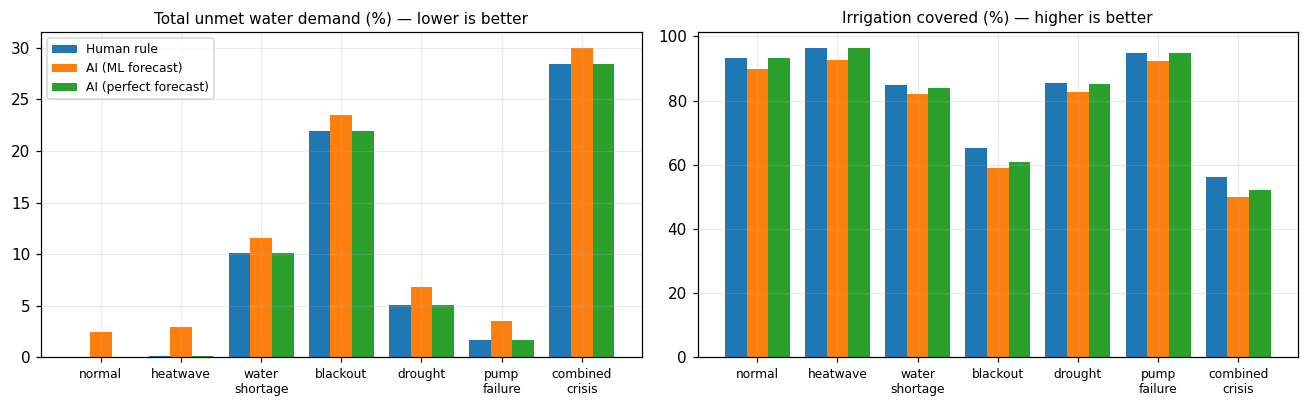

Clinic coverage min — human: 68.0 % | AI: 100.0 %


In [14]:
order = SCEN; pols = ["Human rule", "AI (ML forecast)", "AI (perfect forecast)"]
fig, ax = plt.subplots(1, 2, figsize=(12, 3.8))
for j, (col, ttl) in enumerate([("unmet_pct", "Total unmet water demand (%) — lower is better"), ("irrigation_cov", "Irrigation covered (%) — higher is better")]):
    for k, p in enumerate(pols):
        v = [R_[(R_.scenario == s) & (R_.policy == p)][col].mean() for s in order]
        ax[j].bar(np.arange(len(order)) + (k - 1) * .27, v, .27, label=p)
    ax[j].set_xticks(range(len(order))); ax[j].set_xticklabels([s.replace("_", "\n") for s in order], fontsize=8); ax[j].set_title(ttl, fontsize=10)
ax[0].legend(fontsize=8); plt.tight_layout(); plt.show()
print("Clinic coverage min — human: %.1f %% | AI: %.1f %%" % (R_[R_.policy == "Human rule"].clinic_cov.min(), R_[R_.policy == "AI (ML forecast)"].clinic_cov.min()))

## 10. One full 24-hour recommendation (what the dashboard / API would return)

Day 2020-06-08  scenario=combined_crisis  start reservoir=1772 m³  battery=74 kWh
Predicted risk: {'water': 'LOW', 'energy': 'HIGH', 'agri': 'MEDIUM'}
        clinic  household  olive  cereal    veg  forecast_solar_kWh  grid_up  \
00-06h     3.0       45.0  439.0     0.0  152.0                22.0        1   
06-12h     6.0      140.0   11.0     0.0    0.0                 4.0        0   
12-18h     7.0      143.0  123.0     0.0   43.0               555.0        1   
18-24h     6.0      123.0  374.0     0.0  131.0               630.0        0   

        reservoir_end_m3  battery_end_kWh  
00-06h            1194.0             95.0  
06-12h            1099.0              0.0  
12-18h             845.0            362.0  
18-24h             274.0            600.0  
                Human rule  AI plan
unmet_pct             19.9     19.9
clinic_cov           100.0    100.0
household_cov         94.5     94.5
irrigation_cov        75.8     75.8
energy_kwh          1013.8   1013.8
end_reservoi

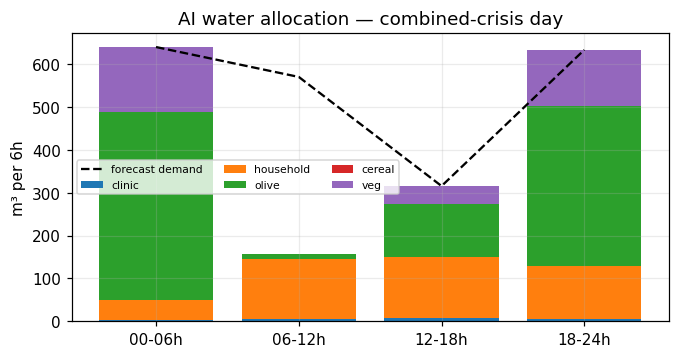

In [15]:
cand = [i for i in test_idx if scen[i] == "combined_crisis" and pd.Timestamp(AR["dates"][i]).month in (6, 7, 8)] or [i for i in test_idx if scen[i] == "combined_crisis"]   # a summer crisis day, when irrigation matters
i = cand[0]; j = pos[i]
dem_f, sol_f = F_dem[j], F_sol[j]
X1 = cls_features({k: (v[[i]] if hasattr(v, "__len__") and len(v) == nd else v) for k, v in AR.items()}, dem_f[None], sol_f[None])
risk = {n: ["LOW", "MEDIUM", "HIGH"][int(clfs[n].predict(X1)[0])] for n in clfs}
plan = solve_lp(AR["R0"][i], AR["B0"][i], dem_f, sol_f, AR["grid"][i], AR["pump"][i], AR["rech"][i])
blocks = ["00-06h", "06-12h", "12-18h", "18-24h"]
rec = pd.DataFrame(plan["water"], columns=SECTORS, index=blocks).round(0)
rec["forecast_solar_kWh"] = sol_f.round(0); rec["grid_up"] = AR["grid"][i]; rec["reservoir_end_m3"] = plan["reservoir"].round(0); rec["battery_end_kWh"] = plan["battery"].round(0)
print(f"Day {pd.Timestamp(AR['dates'][i]).date()}  scenario={scen[i]}  start reservoir={AR['R0'][i]:.0f} m³  battery={AR['B0'][i]:.0f} kWh")
print("Predicted risk:", risk)
display(rec) if "display" in globals() else print(rec)

hum, ai = run_day("human", AR, i), run_day("lp", AR, i, (FD_full, FS_full))
cmp_ = pd.DataFrame({"Human rule": metrics(hum), "AI plan": metrics(ai)}).round(1)
display(cmp_) if "display" in globals() else print(cmp_)

d = ai["dem"].sum(0); s = ai["served"].sum(0)
print("\nExplanation:")
print(f"• Clinic {100*s[0]/d[0]:.0f}% and households {100*s[1]/d[1]:.0f}% of demand covered (protected by the declared priority weights).")
cov = lambda k: "no demand today" if d[k] < 1 else f"{100*s[k]/d[k]:.0f}%"
print(f"• Olive {cov(2)}, cereal {cov(3)}, vegetables {cov(4)} — when resources are short, the lowest-priority crops (vegetables, then cereal) are cut first by policy.")
print(f"• Remaining at midnight: reservoir {ai['end_R']:.0f} m³, battery {ai['end_B']:.0f} kWh.")

fig, ax = plt.subplots(figsize=(7, 3.4)); bottom = np.zeros(4)
for k, sname in enumerate(SECTORS):
    ax.bar(blocks, plan["water"][:, k], bottom=bottom, label=sname); bottom += plan["water"][:, k]
ax.plot(blocks, dem_f.sum(1), "k--", label="forecast demand"); ax.set_ylabel("m³ per 6h"); ax.legend(fontsize=7, ncol=3)
ax.set_title("AI water allocation — combined-crisis day"); plt.show()

## 10b. Reality checks with the two extra files (optional)
- **PVGIS monthly temperature (36.327 N, 9.539 E):** compared with the Open-Meteo weather the model actually uses. If the two curves differ a lot, the weather file is *not* the same place as your site.
- **FAO-style agricultural water withdrawals:** Tunisia's yearly national total, shown next to the simulated irrigation of one small site. They are different scales (country vs one community); the point is only to check we are not off by orders of magnitude per hectare.

In [16]:
MON3 = {m: i + 1 for i, m in enumerate(["Jan","Feb","Mar","Apr","May","Jun","Jul","Aug","Sep","Oct","Nov","Dec"])}
if P_PVGIS:
    rows = []
    for l in open(P_PVGIS, encoding="utf-8"):
        p = l.strip().split()
        if len(p) == 3 and p[0].isdigit() and p[1] in MON3:
            rows.append((int(p[0]), MON3[p[1]], float(p[2])))
    pv = pd.DataFrame(rows, columns=["year", "month", "t2m"])
    om = six[["time", "temperature_2m"]].copy(); om["temperature_2m"] = pd.to_numeric(om.temperature_2m, errors="coerce")
    om = om.dropna(); om = om[(om.time.dt.year >= pv.year.min()) & (om.time.dt.year <= pv.year.max())]
    cmp_t = pd.DataFrame({"PVGIS site (36.33N)": pv.groupby("month").t2m.mean(),
                          "Open-Meteo file used": om.groupby(om.time.dt.month).temperature_2m.mean()}).round(1)
    cmp_t["difference"] = (cmp_t.iloc[:, 1] - cmp_t.iloc[:, 0]).round(1)
    print(cmp_t.T.to_string())
    print(f"\nAverage difference over the year: {cmp_t['difference'].mean():+.1f} °C")
    cmp_t.iloc[:, :2].plot(figsize=(7, 3), title="Monthly mean temperature, 2005-2023"); plt.ylabel("°C"); plt.show()
else:
    print("PVGIS file not found - skipped")

if P_WATER:
    wd = pd.read_csv(P_WATER); wd = wd[wd.Entity == "Tunisia"].sort_values("Year")
    wd["km3"] = wd.iloc[:, 3] / 1e9
    print(f"Tunisia agricultural water withdrawal: {wd.km3.iloc[-1]:.2f} km³ in {int(wd.Year.iloc[-1])} (range {wd.km3.min():.2f}-{wd.km3.max():.2f} km³ since {int(wd.Year.min())})")
    yr = B.assign(irr=B[[f"dem_{c}" for c in CROPS]].sum(axis=1)).groupby(B.date.dt.year).irr.sum()
    yr = yr[yr.index.isin(range(2001, 2026))]
    ha = sum(AREA_HA.values())
    print(f"Simulated site irrigation: {yr.mean():,.0f} m³/year on {ha} ha = {yr.mean()/ha:,.0f} m³ per hectare per year")
    print("(Typical irrigated farmland uses a few thousand m³/ha/year; the number above should be in that order of magnitude.)")
else:
    print("Water-withdrawal file not found - skipped")

PVGIS file not found - skipped
Water-withdrawal file not found - skipped


## 10c. Rain prediction (NEW)
**You give:** temperature, humidity, wind, a sky description (`clear` / `partly cloudy` / `cloudy`, or a WMO weather code), the hour and the month.
**It answers (for one 6 h block):**
1. Will it rain? (Random Forest classifier → probability + yes/no)
2. If yes, how many mm? (Random Forest regressor trained on rainy blocks only)

**Data:** the models are trained on the **real Open-Meteo rain** (not the simulator, and without the synthetic heatwave anomaly). The Tunisia rainfall CSV (`tun-rainfall-subnat-5ytd.csv`) holds 10-day regional totals with no temperature, so it cannot train a 6 h model; it is used in the last cell of this section to cross-check monthly totals.

**No cheating with the weather code:** WMO codes 51 and above literally *mean* precipitation, so using them would make the question trivial. The sky is collapsed to clear / partly cloudy / overcast, which carries no rain information.

In [17]:
from sklearn.metrics import roc_auc_score, brier_score_loss, precision_recall_fscore_support

WET_MM = 0.1                              # a 6 h block counts as "rain" from 0.1 mm

def sky_class(code):
    """0 clear, 1 partly cloudy, 2 overcast/fog/anything else (precipitation codes are merged here on purpose: no leakage)."""
    code = np.asarray(code)
    return np.where(code == 0, 0, np.where(code <= 2, 1, 2))

# ---- real rain data from the Open-Meteo file (no simulator, no synthetic anomaly) ----
rw = six[["time", "temperature_2m", "rain", "relative_humidity_2m", "weather_code", "wind_speed_10m"]].copy()
rw.columns = ["time", "temp", "rain", "rh", "wcode", "wind"]
for c in rw.columns[1:]:
    rw[c] = pd.to_numeric(rw[c], errors="coerce")
rw = rw.dropna().sort_values("time").reset_index(drop=True)
rw["wind"] = rw.wind / 3.6                                   # km/h -> m/s (same as the simulator)
rw["hour"], rw["month"] = rw.time.dt.hour, rw.time.dt.month
rw["sky"] = sky_class(rw.wcode)
rw["rain_mm"] = rw.rain * 6                                  # mm per 6 h block (same convention as the simulator)
rw["wet"] = (rw.rain_mm >= WET_MM).astype(int)

RAIN_FEATS = ["temp", "rh", "wind", "hour", "month", "sky"]
tr, te = rw[rw.time.dt.year <= 2019], rw[rw.time.dt.year >= 2020]
print(f"rainy blocks: train {tr.wet.mean():.1%}, test {te.wet.mean():.1%}")

# 1) rain yes/no
rain_clf = RandomForestClassifier(n_estimators=300, max_depth=10, min_samples_leaf=5, oob_score=True,
                                  random_state=SEED, n_jobs=-1).fit(tr[RAIN_FEATS], tr.wet)
oob = np.nan_to_num(rain_clf.oob_decision_function_[:, 1])
ths = np.linspace(.05, .8, 76)
RAIN_THR = float(ths[int(np.argmax([f1_score(tr.wet, oob >= t) for t in ths]))])     # threshold chosen on TRAIN out-of-bag only
p = rain_clf.predict_proba(te[RAIN_FEATS])[:, 1]; yhat = (p >= RAIN_THR).astype(int)
pr, rc, f1, _ = precision_recall_fscore_support(te.wet, yhat, labels=[1], zero_division=0)
print(f"\nRain classifier on test years (threshold {RAIN_THR:.2f}):")
print(f"  precision {pr[0]:.2f} | recall {rc[0]:.2f} | F1 {f1[0]:.2f} | ROC-AUC {roc_auc_score(te.wet, p):.3f}")
print(f"  Brier {brier_score_loss(te.wet, p):.4f}  vs  'always the average rain rate' {brier_score_loss(te.wet, np.full(len(te), tr.wet.mean())):.4f} (lower is better)")

# 2) how many mm, given that it rains
trw, tew = tr[tr.wet == 1], te[te.wet == 1]
rain_amt = RandomForestRegressor(n_estimators=300, max_depth=10, min_samples_leaf=5, random_state=SEED, n_jobs=-1).fit(trw[RAIN_FEATS], trw.rain_mm)
mae = mean_absolute_error(tew.rain_mm, rain_amt.predict(tew[RAIN_FEATS]))
base = mean_absolute_error(tew.rain_mm, np.full(len(tew), trw.rain_mm.median()))
print(f"\nRain amount (rainy test blocks only): MAE {mae:.2f} mm per 6 h vs {base:.2f} mm for 'always the typical amount'")
print(f"Typical rainy block: median {trw.rain_mm.median():.1f} mm, 95th percentile {trw.rain_mm.quantile(.95):.1f} mm")

rainy blocks: train 5.5%, test 5.3%

Rain classifier on test years (threshold 0.32):
  precision 0.46 | recall 0.65 | F1 0.54 | ROC-AUC 0.963
  Brier 0.0324  vs  'always the average rain rate' 0.0501 (lower is better)

Rain amount (rainy test blocks only): MAE 6.51 mm per 6 h vs 5.85 mm for 'always the typical amount'
Typical rainy block: median 3.0 mm, 95th percentile 29.6 mm


In [18]:
SKY_WORDS = {"clear": 0, "sunny": 0, "partly cloudy": 1, "cloudy": 2, "overcast": 2, "fog": 2}

def predict_rain(temp_c, rh, wind_kmh=10.0, weather="cloudy", hour=12, month=None):
    """One 6 h block. weather: 'clear' | 'partly cloudy' | 'cloudy' or a WMO weather code (int). hour: 0, 6, 12 or 18 (any hour is mapped to its block)."""
    month = month or pd.Timestamp.today().month
    sky = int(sky_class(weather)) if isinstance(weather, (int, np.integer)) else SKY_WORDS[str(weather).lower().replace("_", " ")]
    X = pd.DataFrame([dict(temp=temp_c, rh=rh, wind=wind_kmh / 3.6, hour=6 * (int(hour) // 6), month=month, sky=sky)])[RAIN_FEATS]
    prob = float(rain_clf.predict_proba(X)[0, 1]); will = prob >= RAIN_THR
    mm_if = max(float(rain_amt.predict(X)[0]), 0.0)
    return dict(rain=("YES" if will else "NO"), probability=round(prob, 2),
                mm_if_it_rains=round(mm_if, 1), expected_mm=round(prob * mm_if, 2))

examples = [
    dict(temp_c=12, rh=90, wind_kmh=25, weather="cloudy",        hour=6,  month=1),
    dict(temp_c=18, rh=75, wind_kmh=20, weather="cloudy",        hour=18, month=11),
    dict(temp_c=24, rh=55, wind_kmh=15, weather="partly cloudy", hour=12, month=4),
    dict(temp_c=36, rh=20, wind_kmh=10, weather="clear",         hour=12, month=7),
]
out = pd.DataFrame([{**e, **predict_rain(**e)} for e in examples])
print("Predictions for 4 example blocks (edit `examples` or call predict_rain(...) yourself):")
display(out) if "display" in globals() else print(out.to_string())

Predictions for 4 example blocks (edit `examples` or call predict_rain(...) yourself):
   temp_c  rh  wind_kmh        weather  hour  month rain  probability  mm_if_it_rains  expected_mm
0      12  90        25         cloudy     6      1  YES         0.43            23.1        10.01
1      18  75        20         cloudy    18     11  YES         0.75            10.9         8.14
2      24  55        15  partly cloudy    12      4   NO         0.01             4.9         0.05
3      36  20        10          clear    12      7   NO         0.00             2.4         0.00


level-1 regions in the file: ['TN1', 'TN2', 'TN3', 'TN4', 'TN5', 'TN6']
321 common months | correlation 0.65 | total CSV 9088 mm vs site 15724 mm


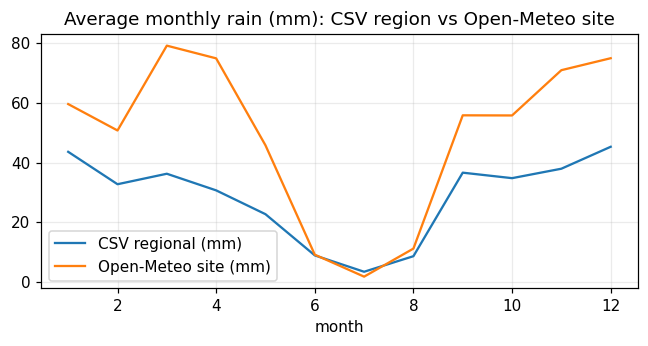

(A region average and one grid point will not match exactly; the seasonal shape and the order of magnitude should agree.)


In [19]:
# Cross-check: monthly rain at the site (Open-Meteo) vs regional totals in the Tunisia rainfall CSV
P_RAIN = find("tun-rainfall-subnat*.csv", required=False)
RAIN_PCODE = None            # e.g. "TN1" to use one region; None = average of all level-1 regions
if P_RAIN:
    cr = pd.read_csv(P_RAIN, parse_dates=["date"])
    print("level-1 regions in the file:", sorted(cr[cr.adm_level == 1].PCODE.unique()))
    sel = cr[cr.PCODE == RAIN_PCODE] if RAIN_PCODE else cr[cr.adm_level == 1]
    s = sel.groupby("date").rfh.mean()                                   # rfh = rain per 10-day period (mm)
    csv_m = s.groupby([s.index.year, s.index.month]).sum().rename("CSV regional (mm)").rename_axis(["year", "month"])
    om_m = rw.groupby([rw.time.dt.year, rw.time.dt.month]).rain_mm.sum().rename("Open-Meteo site (mm)").rename_axis(["year", "month"])
    cmp_r = pd.concat([csv_m, om_m], axis=1).dropna()
    if len(cmp_r) > 3:
        print(f"{len(cmp_r)} common months | correlation {cmp_r.corr().iloc[0, 1]:.2f} | total CSV {cmp_r.iloc[:, 0].sum():.0f} mm vs site {cmp_r.iloc[:, 1].sum():.0f} mm")
        cmp_r.groupby("month").mean().plot(figsize=(7, 3), title="Average monthly rain (mm): CSV region vs Open-Meteo site"); plt.show()
        print("(A region average and one grid point will not match exactly; the seasonal shape and the order of magnitude should agree.)")
    else:
        print("Fewer than 4 common months between the two files - check that Open-Meteo covers 2022 onward.")
else:
    print("Rainfall CSV not found - skipped")

In [ ]:
%pip install -q flask pyngrok openai

# OpenAI API key: add OPENAI_API_KEY to Colab Secrets.
# Outside Colab, set it as an environment variable instead.
import os
from dotenv import load_dotenv
from openai import OpenAI

# Load environment variables from the project folder
load_dotenv(override=True)

# Configure OpenAI
OPENAI_MODEL = os.getenv("OPENAI_MODEL", "gpt-5.5")

api_key = os.getenv("OPENAI_API_KEY")

if not api_key:
    raise ValueError("OPENAI_API_KEY is missing from your .env file")

_openai_client = OpenAI(api_key=api_key)

print("NEXUS ExplainAI initialized successfully!")

# ------------------------------------------------------------------ planner (all models)
def scenario_day(date, heat_c, R0_pct, B0_pct, grid, pump_pct, inflow_pct):
    """Real weather of `date` + the situation chosen by the user -> 4 simulator blocks (same engine as section 4)."""
    global make_days
    d = pd.Timestamp(date).normalize()
    sub = six[six.time.dt.normalize().isin([d - pd.Timedelta(days=1), d])]     # previous day gives the 'previous block' features
    if sub.empty:
        raise ValueError("No weather data for that date.")
    def fixed_days(dates, rng_):
        D = pd.DataFrame({"date": dates, "scenario": "custom"})
        D["anom"] = float(heat_c); D["rech_f"] = inflow_pct / 100; D["pump_f"] = pump_pct / 100
        D["R0"] = R0_pct / 100 * R_CAP; D["B0"] = B0_pct / 100 * B_CAP
        for k in range(4):
            D[f"g{k}"] = int(grid[k])
        return D
    original = make_days
    make_days = fixed_days
    try:
        Bd = build_blocks(sub, np.random.default_rng(int(d.strftime("%Y%m%d"))))
    finally:
        make_days = original
    Dd = Bd[Bd.date == d].reset_index(drop=True)
    if len(Dd) != 4:
        raise ValueError("That date has incomplete weather data - pick another day.")
    return Dd

def run_planner(date, heat_c, R0_pct, B0_pct, grid, pump_pct, inflow_pct):
    with _lock:                                                  # make_days is patched temporarily: one request at a time here
        Dd = scenario_day(date, heat_c, R0_pct, B0_pct, grid, pump_pct, inflow_pct)
    a = day_arrays(Dd)
    F_d, F_s = forecast_days(models, Dd)                         # 4 regressors: clinic, household, irrigation (3 crops), solar
    X = cls_features(a, F_d, F_s)
    risk = {}
    for n, clf in clfs.items():                                  # 3 classifiers: water, energy, agri
        pr = clf.predict_proba(X)[0]
        risk[n] = dict(level=LEVELS[int(clf.predict(X)[0])], probs={LEVELS[int(c)]: round(float(p), 2) for c, p in zip(clf.classes_, pr)})
    hum, ai = run_day("human", a, 0), run_day("lp", a, 0, (F_d, F_s))
    pl = ai["plan0"]
    plan = None
    if pl is not None and pl["ok"]:                              # linear programming plan made at the start of the day
        plan = dict(water=_round(pl["water"]), solar_used=_round(pl["solar_used"]), grid=_round(pl["grid"]), batt_discharge=_round(pl["batt_discharge"]),
                    batt_charge=_round(pl["batt_charge"]), reservoir=_round(pl["reservoir"], 0), battery=_round(pl["battery"], 0))
    d_, s_ = ai["dem"].sum(0), ai["served"].sum(0)
    cov = lambda k: "no demand this day" if d_[k] < 1 else f"{100 * s_[k] / d_[k]:.0f}%"
    notes = [f"Clinic {cov(0)} and households {cov(1)} of demand covered (protected by the declared priority weights).",
             f"Olive {cov(2)}, cereal {cov(3)}, vegetables {cov(4)}. When resources are short, vegetables and then cereal are cut first, by policy.",
             f"Left at midnight: reservoir {ai['end_R']:.0f} m³, battery {ai['end_B']:.0f} kWh."]
    mt = lambda r: {k: round(float(v), 1) for k, v in metrics(r).items()}

    # Actual deliveries for each 6-hour block (not just the LP's proposed plan).
    def _served_rows(result):
        return [
            {SECTORS[k]: round(float(result["served"][t, k]), 2) for k in range(5)}
            for t in range(4)
        ]

    def _demand_rows(result):
        return [
            {SECTORS[k]: round(float(result["dem"][t, k]), 2) for k in range(5)}
            for t in range(4)
        ]

    # Capture the actual decision rules and numerical evidence for ExplainAI.
    explanation_context = {
        "human_strategy": {
            "rule": (
                "At each 6-hour block, requests the full simulated demand. "
                "The execute() simulator applies physical limits and serves "
                "sectors sequentially in SECTORS order: " + " -> ".join(SECTORS) + "."
            ),
            "actual_demand_by_block_m3": _demand_rows(hum),
            "actually_delivered_by_block_m3": _served_rows(hum),
            "performance_metrics": mt(hum),
            "ending_reservoir_m3": round(float(hum["end_R"]), 2),
            "ending_battery_kwh": round(float(hum["end_B"]), 2),
            "pumping_energy_kwh": round(float(hum["energy"]), 2),
            "energy_shortfall_indicator": round(float(hum["lost_energy"]), 2)
        },
        "nexus_strategy": {
            "rule": (
                "Uses rolling-horizon Linear Programming with predicted demand "
                "and solar. Clinic and household requests are topped up to "
                "simulated actual demand before physical execution. The optimizer "
                "accounts for water, pumping energy, solar, grid, battery, pump "
                "capacity and terminal reservoir/battery values."
            ),
            "actual_demand_by_block_m3": _demand_rows(ai),
            "actually_delivered_by_block_m3": _served_rows(ai),
            "initial_lp_water_plan_m3": (
                _round(pl["water"], 2) if pl is not None and pl.get("ok") else None
            ),
            "performance_metrics": mt(ai),
            "ending_reservoir_m3": round(float(ai["end_R"]), 2),
            "ending_battery_kwh": round(float(ai["end_B"]), 2),
            "pumping_energy_kwh": round(float(ai["energy"]), 2),
            "energy_shortfall_indicator": round(float(ai["lost_energy"]), 2)
        },
        "lp_configuration": {
            "sector_order": list(SECTORS),
            "sector_priority_weights": np.asarray(W, dtype=float).tolist(),
            "energy_per_m3": float(E_PUMP),
            "grid_cost": float(GRID_COST),
            "terminal_reservoir_value": float(V_WATER),
            "terminal_battery_value": float(V_BATT),
            "battery_efficiency": float(ETA),
            "irrigation_forecast_safety_factor": float(IRR_SAFETY)
        }
    }

    return dict(date=str(pd.Timestamp(date).date()), blocks=BLOCKS, sectors=SECTORS,
                start=dict(reservoir=round(float(a["R0"][0])), battery=round(float(a["B0"][0])), grid=[int(g) for g in a["grid"][0]],
                           pump=round(float(a["pump"][0])), inflow=_round(a["rech"][0], 0), temp=round(float(a["temp"][0]), 1)),
                forecast=dict(demand=_round(F_d[0]), solar=_round(F_s[0])),
                simulated_actual=dict(demand=_round(a["dem"][0]), solar=_round(a["solar"][0])),
                risk=risk, plan=plan, comparison=dict(human=mt(hum), ai=mt(ai)),
                notes=notes, explanation_context=explanation_context)

# ------------------------------------------------------------------ web page
PAGE = r"""<!doctype html>
<html lang="en"><head><meta charset="utf-8"><meta name="viewport" content="width=device-width,initial-scale=1">
<title>NEXUS 24</title>
<style>
 :root{--bg:#f4f6f8;--card:#fff;--ink:#1c2733;--mute:#66758a;--line:#dde3ea;--acc:#1f6fd1;--ok:#2e8b57;--mid:#d98e1a;--bad:#d33f49}
 @media(prefers-color-scheme:dark){:root{--bg:#10161d;--card:#18212b;--ink:#e8edf3;--mute:#93a1b3;--line:#2a3643;--acc:#5aa2f5;--ok:#4fb97f;--mid:#e0a040;--bad:#ef6b73}}
 *{box-sizing:border-box} body{margin:0;background:var(--bg);color:var(--ink);font:16px/1.45 system-ui,Segoe UI,Roboto,sans-serif}
 main{max-width:760px;margin:0 auto;padding:16px 16px 48px} h1{font-size:1.35rem;margin:4px 0 2px} h2{font-size:1.02rem;margin:0 0 8px}
 p.sub{margin:0 0 14px;color:var(--mute);font-size:.92rem} .small{font-size:.82rem;color:var(--mute)}
 .tabs{display:flex;gap:8px;margin:0 0 14px} .tabs button{flex:1;margin:0;background:var(--card);color:var(--ink);border:1px solid var(--line)} .tabs button.on{background:var(--acc);color:#fff;border-color:var(--acc)}
 .card{background:var(--card);border:1px solid var(--line);border-radius:14px;padding:16px;margin-bottom:14px}
 label{display:block;font-size:.85rem;color:var(--mute);margin:10px 0 4px}
 input,select{width:100%;padding:10px 12px;font:inherit;color:var(--ink);background:var(--bg);border:1px solid var(--line);border-radius:10px}
 input[type=range]{padding:0} input[type=checkbox]{width:auto}
 .row{display:grid;grid-template-columns:1fr 1fr;gap:12px} .grid4{display:grid;grid-template-columns:repeat(4,1fr);gap:8px}
 .grid4 label{display:flex;gap:6px;align-items:center;margin:4px 0;color:var(--ink);font-size:.82rem}
 button{width:100%;margin-top:16px;padding:12px;font:inherit;font-weight:600;color:#fff;background:var(--acc);border:0;border-radius:10px;cursor:pointer} button:disabled{opacity:.6}
 .err{color:var(--bad);margin-top:10px;display:none} .hide{display:none}
 .badges{display:grid;grid-template-columns:repeat(3,1fr);gap:10px} .badge{border-radius:12px;padding:12px;text-align:center;color:#fff}
 .badge b{display:block;font-size:1.15rem} .badge span{font-size:.78rem;opacity:.92} .LOW{background:var(--ok)} .MEDIUM{background:var(--mid)} .HIGH{background:var(--bad)}
 .scroll{overflow-x:auto} table{border-collapse:collapse;width:100%;font-size:.86rem} th,td{padding:6px 8px;text-align:right;border-bottom:1px solid var(--line);white-space:nowrap} th:first-child,td:first-child{text-align:left}
 th{color:var(--mute);font-weight:600} .legend{display:flex;flex-wrap:wrap;gap:10px;margin-top:6px;font-size:.8rem} .legend i{display:inline-block;width:10px;height:10px;border-radius:2px;margin-right:4px}
 .bar{height:10px;background:var(--line);border-radius:6px;overflow:hidden;margin:6px 0 12px}.bar>div{height:100%;background:var(--acc);width:0}
 .kv{display:flex;justify-content:space-between;padding:6px 0;border-top:1px solid var(--line)} .kv span:first-child{color:var(--mute)} ul{margin:6px 0 0;padding-left:18px}
</style></head><body><main>
<h1>NEXUS 24</h1><p class="sub">Water · energy · agriculture decision support (simulated site) and rain prediction.</p>
<div class="tabs"><button class="on" data-tab="plan" type="button">24 h planner</button><button data-tab="rain" type="button">Rain</button></div>

<section id="tab-plan">
 <form id="pf" class="card">
  <div class="row">
   <div><label>Date (real weather of that day)</label><input id="date" type="date" required></div>
   <div><label>Situation preset</label><select id="preset"><option value="normal">Normal</option><option value="heatwave">Heatwave</option><option value="water_shortage">Water shortage</option><option value="blackout">Blackout</option><option value="drought">Drought</option><option value="pump_failure">Pump failure</option><option value="combined_crisis">Combined crisis</option></select></div>
  </div>
  <label>Extra heat: <b id="v_heat"></b> °C</label><input id="heat" type="range" min="0" max="12" step="0.5">
  <label>Reservoir level: <b id="v_res"></b> %</label><input id="res" type="range" min="0" max="100" step="1">
  <label>Battery charge: <b id="v_bat"></b> %</label><input id="bat" type="range" min="0" max="100" step="1">
  <label>Pump capacity: <b id="v_pump"></b> %</label><input id="pump" type="range" min="10" max="100" step="5">
  <label>Water inflow (springs, runoff): <b id="v_inflow"></b> % of normal</label><input id="inflow" type="range" min="20" max="110" step="5">
  <label>Grid available in each 6 h block</label>
  <div class="grid4"><label><input type="checkbox" class="g" checked>00-06h</label><label><input type="checkbox" class="g" checked>06-12h</label><label><input type="checkbox" class="g" checked>12-18h</label><label><input type="checkbox" class="g" checked>18-24h</label></div>
  <button id="pb" type="submit">Run all models</button><div class="err" id="perr"></div>
 </form>
 <div id="pres" class="hide">
  <div class="card"><h2>Shortage risk (3 classifiers)</h2><div class="badges" id="badges"></div><p class="small" id="start"></p></div>
  <div class="card"><h2>Recommended water plan (linear programming)</h2><div id="chart"></div><div class="legend" id="legend"></div>
   <div class="scroll"><table id="plan"></table></div><p class="small">Water in m³ per 6 h block. The dashed marks show forecast demand.</p></div>
  <div class="card"><h2>Forecasts (4 regressors)</h2><div class="scroll"><table id="fc"></table></div><p class="small">Demand in m³ per 6 h, solar in kWh per 6 h.</p></div>
  <div class="card"><h2>Human rule vs AI plan</h2><div class="scroll"><table id="cmp"></table></div><ul id="notes"></ul>
   <p class="small">Simulated day: the "actual" demand and solar come from the simulator, as in section 9 of the notebook.</p></div>

  <div class="card" id="explain-card">
   <h2>NEXUS ExplainAI — Decision explanations</h2>
   <p class="small">Understand why the NEXUS optimizer and the human rule produced their choices, and what consequences followed. This explanation uses the results above; it does not change the allocation.</p>
   <button id="explain-btn" type="button">Explain both strategies</button>
   <p id="explain-status" class="small" aria-live="polite"></p>
   <div id="explain-output" style="white-space:pre-wrap;line-height:1.7;margin-top:12px"></div>
  </div>
 </div>
</section>

<section id="tab-rain" class="hide">
 <form id="rf" class="card">
  <div class="row"><div><label>Temperature (°C)</label><input name="temp_c" type="number" step="0.1" value="15" required></div>
  <div><label>Humidity (%)</label><input name="rh" type="number" step="1" min="0" max="100" value="75" required></div></div>
  <div class="row"><div><label>Wind (km/h)</label><input name="wind_kmh" type="number" step="0.1" min="0" value="15" required></div>
  <div><label>Weather</label><select name="weather"><option value="clear">Clear</option><option value="partly cloudy">Partly cloudy</option><option value="cloudy" selected>Cloudy / overcast</option></select></div></div>
  <div class="row"><div><label>Time of day</label><select name="hour"><option value="0">00:00 – 06:00</option><option value="6">06:00 – 12:00</option><option value="12" selected>12:00 – 18:00</option><option value="18">18:00 – 24:00</option></select></div>
  <div><label>Month</label><select name="month" id="month"></select></div></div>
  <button id="rb" type="submit">Predict rain</button><div class="err" id="rerr"></div>
 </form>
 <div id="rres" class="card hide">
  <h2 id="verdict"></h2><div>Probability of rain: <b id="prob"></b></div><div class="bar"><div id="fill"></div></div>
  <div class="kv"><span>Amount if it rains</span><b id="mm"></b></div><div class="kv"><span>Expected rain (probability × amount)</span><b id="exp"></b></div>
 </div>
</section>

<script>
const $=s=>document.querySelector(s), SEC=["Clinic","Households","Olive","Cereal","Vegetables"], COL=["#d6455d","#e0892b","#4a9d5b","#c9b037","#2f8f9d"];
const f0=x=>Number(x).toLocaleString(undefined,{maximumFractionDigits:0}), f1=x=>Number(x).toLocaleString(undefined,{maximumFractionDigits:1,minimumFractionDigits:1});
let HW=5;
document.querySelectorAll(".tabs button").forEach(b=>b.onclick=()=>{
 document.querySelectorAll(".tabs button").forEach(x=>x.classList.toggle("on",x===b));
 $("#tab-plan").classList.toggle("hide",b.dataset.tab!=="plan"); $("#tab-rain").classList.toggle("hide",b.dataset.tab!=="rain");});
const names=["January","February","March","April","May","June","July","August","September","October","November","December"];
names.forEach((n,i)=>$("#month").add(new Option(n,i+1))); $("#month").value=new Date().getMonth()+1;

// ---- planner form
const SL=[["heat","v_heat"],["res","v_res"],["bat","v_bat"],["pump","v_pump"],["inflow","v_inflow"]];
SL.forEach(([i,v])=>{const e=$("#"+i); const u=()=>$("#"+v).textContent=e.value; e.oninput=u; u();});
function setSliders(o){SL.forEach(([i,v])=>{ $("#"+i).value=o[i]; $("#"+v).textContent=o[i]; }); document.querySelectorAll(".g").forEach((c,k)=>c.checked=!!o.grid[k]);}
function preset(n){const h=Math.round(HW*0.75*2)/2, P={
 normal:{heat:0,res:70,bat:80,pump:100,inflow:100,grid:[1,1,1,1]},
 heatwave:{heat:h,res:60,bat:80,pump:100,inflow:100,grid:[1,1,1,1]},
 water_shortage:{heat:0,res:20,bat:80,pump:100,inflow:35,grid:[1,1,1,1]},
 blackout:{heat:0,res:70,bat:25,pump:100,inflow:100,grid:[0,0,1,0]},
 drought:{heat:0,res:10,bat:80,pump:100,inflow:30,grid:[1,1,1,1]},
 pump_failure:{heat:0,res:70,bat:80,pump:35,inflow:100,grid:[1,1,1,1]},
 combined_crisis:{heat:h,res:20,bat:25,pump:35,inflow:35,grid:[0,0,1,0]}}; setSliders(P[n]);}
$("#preset").onchange=e=>preset(e.target.value);
fetch("/api/meta").then(r=>r.json()).then(m=>{HW=m.hw_delta; const d=$("#date"); d.min=m.date_min; d.max=m.date_max; d.value=m.default_date; preset("normal");});

function table(el,head,rows){$(el).innerHTML="<tr>"+head.map(h=>"<th>"+h+"</th>").join("")+"</tr>"+rows.map(r=>"<tr>"+r.map(c=>"<td>"+c+"</td>").join("")+"</tr>").join("");}
function chart(water,dem,blocks){
 const W=560,H=220,L=44,R=8,T=10,B=28,n=4, tot=water.map(r=>r.reduce((a,b)=>a+b,0)), dt=dem.map(r=>r.reduce((a,b)=>a+b,0));
 const mx=Math.max(1,...tot,...dt)*1.1, y=v=>H-B-(H-B-T)*v/mx, slot=(W-L-R)/n, bw=slot*0.5;
 let s=`<svg viewBox="0 0 ${W} ${H}" width="100%" role="img" aria-label="Recommended water per block">`;
 [0,.5,1].forEach(k=>{const yy=y(mx*k); s+=`<line x1="${L}" x2="${W-R}" y1="${yy}" y2="${yy}" stroke="currentColor" opacity=".15"/><text x="${L-6}" y="${yy+4}" font-size="10" text-anchor="end" fill="currentColor" opacity=".7">${f0(mx*k)}</text>`;});
 for(let i=0;i<n;i++){const x=L+slot*i+(slot-bw)/2; let acc=0;
  for(let k=0;k<5;k++){const v=water[i][k]; if(v<=0)continue; const y0=y(acc+v), h=y(acc)-y0; s+=`<rect x="${x}" y="${y0}" width="${bw}" height="${Math.max(h,0)}" fill="${COL[k]}"><title>${SEC[k]}: ${f0(v)} m³</title></rect>`; acc+=v;}
  s+=`<line x1="${x-6}" x2="${x+bw+6}" y1="${y(dt[i])}" y2="${y(dt[i])}" stroke="currentColor" stroke-width="2" stroke-dasharray="4 3"/>`;
  s+=`<text x="${x+bw/2}" y="${H-10}" font-size="11" text-anchor="middle" fill="currentColor">${blocks[i]}</text>`;}
 return s+"</svg>";}
$("#pf").addEventListener("submit",async e=>{
 e.preventDefault(); const b=$("#pb"), err=$("#perr"); err.style.display="none"; b.disabled=true; b.textContent="Running models…";
 const body={date:$("#date").value,heat_c:+$("#heat").value,reservoir_pct:+$("#res").value,battery_pct:+$("#bat").value,pump_pct:+$("#pump").value,inflow_pct:+$("#inflow").value,grid:[...document.querySelectorAll(".g")].map(c=>c.checked?1:0)};
 try{
  const r=await fetch("/api/plan",{method:"POST",headers:{"Content-Type":"application/json"},body:JSON.stringify(body)}); const d=await r.json(); if(!r.ok) throw new Error(d.error||"Request failed");
  window.lastNexusPlanData = d;
  $("#explain-output").textContent = "";
  $("#explain-status").textContent = "Plan ready. Select Explain both strategies to generate the explanation.";
  $("#badges").innerHTML=[["water","Water"],["energy","Energy"],["agri","Agriculture"]].map(([k,t])=>`<div class="badge ${d.risk[k].level}"><span>${t} risk</span><b>${d.risk[k].level}</b><span>${Object.entries(d.risk[k].probs).map(([a,p])=>a[0]+" "+Math.round(p*100)+"%").join(" · ")}</span></div>`).join("");
  $("#start").textContent=`Start of day: mean temperature ${d.start.temp} °C, reservoir ${f0(d.start.reservoir)} m³, battery ${f0(d.start.battery)} kWh, pump ${f0(d.start.pump)} m³/6h, grid ${d.start.grid.map(g=>g?"up":"down").join(" / ")}.`;
  if(d.plan){ $("#chart").innerHTML=chart(d.plan.water,d.forecast.demand,d.blocks); $("#legend").innerHTML=SEC.map((s,k)=>`<span><i style="background:${COL[k]}"></i>${s}</span>`).join("");
   table("#plan",["Block",...SEC,"Solar→pump kWh","Grid kWh","Battery out kWh","Reservoir end m³","Battery end kWh"],d.blocks.map((bl,i)=>[bl,...d.plan.water[i].map(f0),f0(d.plan.solar_used[i]),f0(d.plan.grid[i]),f0(d.plan.batt_discharge[i]),f0(d.plan.reservoir[i]),f0(d.plan.battery[i])]));
  } else { $("#chart").innerHTML="<p class='small'>The optimizer found no feasible plan for this situation.</p>"; $("#plan").innerHTML=""; $("#legend").innerHTML=""; }
  table("#fc",["Block",...SEC,"Solar kWh"],d.blocks.map((bl,i)=>[bl,...d.forecast.demand[i].map(f1),f0(d.forecast.solar[i])]));
  const M=[["unmet_pct","Unmet water demand (%)"],["clinic_cov","Clinic covered (%)"],["household_cov","Households covered (%)"],["irrigation_cov","Irrigation covered (%)"],["energy_kwh","Pumping energy (kWh)"],["end_reservoir","Reservoir at midnight (m³)"],["end_battery","Battery at midnight (kWh)"]];
  table("#cmp",["","Human rule","AI plan"],M.map(([k,t])=>[t,f1(d.comparison.human[k]),f1(d.comparison.ai[k])]));
  $("#notes").innerHTML=d.notes.map(n=>"<li>"+n+"</li>").join(""); $("#pres").classList.remove("hide");
 }catch(x){err.textContent=x.message; err.style.display="block";}
 b.disabled=false; b.textContent="Run all models";});

// ---- NEXUS ExplainAI
$("#explain-btn").addEventListener("click", async () => {
 const data = window.lastNexusPlanData;
 const button = $("#explain-btn");
 const status = $("#explain-status");
 const output = $("#explain-output");

 if (!data) {
   status.textContent = "Run the 24-hour planner before requesting an explanation.";
   return;
 }

 button.disabled = true;
 button.textContent = "Generating explanation…";
 status.textContent = "ExplainAI is analyzing the actual decisions and results…";
 output.textContent = "";

 try {
   const response = await fetch("/api/explain", {
     method: "POST",
     headers: {"Content-Type": "application/json"},
     body: JSON.stringify(data)
   });
   const result = await response.json();
   if (!response.ok) throw new Error(result.error || "Explanation request failed.");

   // Use textContent: model output is displayed as text, never executed as HTML.
   output.textContent = result.explanation;
   status.textContent = "Explanation generated.";
 } catch (error) {
   status.textContent = error.message;
 } finally {
   button.disabled = false;
   button.textContent = "Explain both strategies";
 }
});


// ---- rain form
$("#rf").addEventListener("submit",async e=>{
 e.preventDefault(); const b=$("#rb"), err=$("#rerr"); err.style.display="none"; b.disabled=true;
 const f=new FormData(e.target), body={temp_c:+f.get("temp_c"),rh:+f.get("rh"),wind_kmh:+f.get("wind_kmh"),weather:f.get("weather"),hour:+f.get("hour"),month:+f.get("month")};
 try{
  const r=await fetch("/predict-rain",{method:"POST",headers:{"Content-Type":"application/json"},body:JSON.stringify(body)}); const d=await r.json(); if(!r.ok) throw new Error(d.error||"Request failed");
  const rain=d.rain==="YES", v=$("#verdict"); v.textContent=rain?"Rain expected":"No rain expected"; v.style.color=rain?"var(--acc)":"var(--mid)";
  $("#prob").textContent=Math.round(d.probability*100)+" %"; $("#fill").style.width=Math.round(d.probability*100)+"%";
  $("#mm").textContent=d.mm_if_it_rains+" mm"; $("#exp").textContent=d.expected_mm+" mm"; $("#rres").classList.remove("hide");
 }catch(x){err.textContent=x.message; err.style.display="block";}
 b.disabled=false;});
</script></main></body></html>"""

# ------------------------------------------------------------------ API
app = Flask(__name__)
ALLOWED_WEATHER = ["clear", "partly cloudy", "cloudy"]

@app.route("/")
def home():
    return PAGE

@app.route("/health")
def health():
    return jsonify(status="ok")

@app.route("/api/meta")
def api_meta():
    jul = B.date[B.date.dt.month == 7]
    default = (jul.max() if len(jul) else B.date.max())
    return jsonify(date_min=str(B.date.min().date()), date_max=str(B.date.max().date()), default_date=str(default.date()), hw_delta=round(float(HW_DELTA), 1))

@app.route("/api/plan", methods=["POST"])
def api_plan():
    d = request.get_json(silent=True) or {}
    try:
        date = pd.Timestamp(d["date"]); heat = float(d.get("heat_c", 0)); r0 = float(d.get("reservoir_pct", 60)); b0 = float(d.get("battery_pct", 60))
        pump = float(d.get("pump_pct", 100)); inflow = float(d.get("inflow_pct", 100)); grid = [int(bool(x)) for x in d.get("grid", [1, 1, 1, 1])]
        if len(grid) != 4:
            raise ValueError
    except (KeyError, ValueError, TypeError):
        return jsonify(error="Check the form: a valid date and numbers are required."), 400
    if not (B.date.min() <= date <= B.date.max() and 0 <= heat <= 15 and 0 <= r0 <= 100 and 0 <= b0 <= 100 and 5 <= pump <= 100 and 10 <= inflow <= 150):
        return jsonify(error=f"A value is out of range (date must be between {B.date.min().date()} and {B.date.max().date()})."), 400
    try:
        return jsonify(run_planner(date, heat, r0, b0, grid, pump, inflow))
    except ValueError as e:
        return jsonify(error=str(e)), 400
    except Exception as e:
        return jsonify(error=f"Server error: {e}"), 500

def generate_decision_explanation(plan_data):
    """Explain the already-computed human and NEXUS decisions; never make new allocations."""
    if _openai_client is None:
        raise RuntimeError(
            "OpenAI API key is not configured. Add OPENAI_API_KEY to Colab Secrets and rerun this cell."
        )

    instructions = """
You are NEXUS ExplainAI, an explainability assistant for a water, energy
and agriculture resource-allocation simulator.

Explain the supplied results in four sections:
A. WHY NEXUS OPTIMIZATION MADE ITS CHOICES
B. WHY THE HUMAN RULE MADE ITS CHOICES
C. CONSEQUENCES OF THE TWO CHOICES
D. OVERALL COMPARISON

Use only the supplied JSON evidence. Explain the human strategy as a
programmed sequential rule, not as a real person's private thoughts.
Explain the LP using the provided objective weights, forecasts, constraints,
initial LP plan and actual delivered quantities. Clearly distinguish the
optimizer's proposed plan from quantities actually delivered by simulation.

Compare unmet demand, clinic and household coverage, irrigation coverage,
pumping energy, ending reservoir and ending battery when those values exist.
Refer to the shortage-risk predictions where relevant, but do not claim that
risk labels directly caused the LP solution unless the supplied objective
or code shows that relationship.

Never invent values, constraints, motives, or causal explanations.
If a metric is absent, say it was not supplied. Mention that the demand and
crisis scenario are simulator-generated. Do not modify or recommend changing
the calculated allocation. Use clear, concise language suitable for a
university project dashboard.
"""

    response = _openai_client.responses.create(
        model=OPENAI_MODEL,
        instructions=instructions,
        input=json.dumps(plan_data, ensure_ascii=False, default=str)
    )
    return response.output_text


@app.route("/api/explain", methods=["POST"])
def api_explain():
    data = request.get_json(silent=True) or {}
    # Do not forward arbitrary large client payloads to the model.
    if not isinstance(data, dict) or "explanation_context" not in data:
        return jsonify(error="Run the 24-hour planner first; explanation data is missing."), 400
    try:
        explanation_input = {
            "date": data.get("date"),
            "blocks": data.get("blocks"),
            "sectors": data.get("sectors"),
            "start_conditions": data.get("start"),
            "forecasts": data.get("forecast"),
            "shortage_risk_predictions": data.get("risk"),
            "human_vs_nexus_performance": data.get("comparison"),
            "existing_optimizer_notes": data.get("notes"),
            "decision_evidence": data.get("explanation_context")
        }
        explanation = generate_decision_explanation(explanation_input)
        return jsonify(success=True, explanation=explanation)
    except Exception:
        app.logger.exception("NEXUS ExplainAI request failed")
        return jsonify(error="ExplainAI could not generate the explanation. Check the API key, model access and API billing."), 502


@app.route("/predict-rain", methods=["POST"])
def api_predict_rain():
    d = request.get_json(silent=True) or {}
    try:
        temp_c, rh = float(d["temp_c"]), float(d["rh"])
        wind = float(d.get("wind_kmh", 10)); hour = int(d.get("hour", 12))
        month = int(d.get("month", pd.Timestamp.today().month)); weather = str(d.get("weather", "cloudy")).lower().replace("_", " ")
    except (KeyError, ValueError, TypeError):
        return jsonify(error="Please fill temperature and humidity with numbers."), 400
    if not (-30 <= temp_c <= 60 and 0 <= rh <= 100 and 0 <= wind <= 250 and 0 <= hour <= 23 and 1 <= month <= 12 and weather in ALLOWED_WEATHER):
        return jsonify(error="A value is out of range (humidity 0-100 %, month 1-12, weather clear / partly cloudy / cloudy)."), 400
    return jsonify(predict_rain(temp_c, rh, wind, weather, hour, month))

logging.getLogger("werkzeug").setLevel(logging.ERROR)
try:
    _srv.shutdown()                                   # re-running this cell: stop the previous server first
except Exception:
    pass
_srv = make_server("0.0.0.0", 8000, app, threaded=True)
threading.Thread(target=_srv.serve_forever, daemon=True).start()
print("Web app running inside Colab on port 8000 (next cell makes it public).")

SyntaxError: '(' was never closed (3768249106.py, line 22)

## 11. Save everything
Models are compressed with joblib. This creates `nexus24_outputs.zip` and (in Colab) downloads it.

In [23]:
os.makedirs("nexus_outputs", exist_ok=True)
for k, m in models.items(): joblib.dump(m, f"nexus_outputs/reg_{k}.joblib", compress=3)
for k, m in clfs.items(): joblib.dump(m, f"nexus_outputs/clf_{k}.joblib", compress=3)
joblib.dump(rain_clf, "nexus_outputs/rain_classifier.joblib", compress=3); joblib.dump(rain_amt, "nexus_outputs/rain_amount.joblib", compress=3)
reg_report.to_csv("nexus_outputs/regression_metrics.csv", index=False); reg_comparison.to_csv("nexus_outputs/regressor_model_comparison.csv", index=False); cls_comparison.to_csv("nexus_outputs/classifier_model_comparison.csv", index=False); summary.to_csv("nexus_outputs/human_vs_ai_summary.csv")
rec.to_csv("nexus_outputs/example_24h_recommendation.csv")
B.sample(5000, random_state=SEED).to_csv("nexus_outputs/synthetic_sample.csv", index=False)
with zipfile.ZipFile("nexus24_outputs.zip", "w", zipfile.ZIP_DEFLATED) as z:
    for f in os.listdir("nexus_outputs"): z.write(os.path.join("nexus_outputs", f), f)
print("saved:", sorted(os.listdir("nexus_outputs")))
try:
    from google.colab import files; files.download("nexus24_outputs.zip")
except Exception:
    pass

saved: ['classifier_model_comparison.csv', 'clf_agri.joblib', 'clf_energy.joblib', 'clf_water.joblib', 'example_24h_recommendation.csv', 'human_vs_ai_summary.csv', 'rain_amount.joblib', 'rain_classifier.joblib', 'reg_clinic.joblib', 'reg_household.joblib', 'reg_irrigation.joblib', 'reg_solar.joblib', 'regression_metrics.csv', 'regressor_model_comparison.csv', 'synthetic_sample.csv']


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

## Important limits (please keep in your report)
- Demand, solar and all crisis states are **simulation-generated**; metrics measure how well the models learn the simulator, not a real site.
- Weather used for the 24 h forecast is archived real weather (perfect weather forecast). Real use needs a forecast feed.
- Resolution is 6-hourly because of the Open-Meteo export; for hourly planning download the hourly variables and re-run.
- Priority weights, crop areas, population, pump/battery sizes are declared assumptions.
- Validate with real measurements (reservoir, pump, meter data) before any operational claim.
- Rain prediction (section 10c) is trained on real Open-Meteo rain; in real use its quality depends on the quality of the temperature/weather inputs you provide.
- Model selection is based on held-out 2020+ metrics: MAE for regression and macro-F1 for classification. This is a temporal holdout, but the synthetic target-generation process still limits real-world interpretation.
- XGBoost is included when the `xgboost` package is available; otherwise the notebook compares AdaBoost and HistGradientBoosting as the boosting alternatives.
- PCA is reported as a diagnostic only. It is not automatically fed into the tree ensembles because that can reduce interpretability without improving their performance.
